# V23 — Diseño de injerto con 5 materiales (líneas truncadas): red de V21, código mínimo, celdas 0 a 21

**Cambios V22 → V23 (no requiere entrenar)**

1. **Red de V21** (peso del crosstalk 20): ganó en las arterias reales y en los sujetos de test. Con `ENTRENAR = False` (Celda 0) se cargan sus archivos. Copiá en esta carpeta:
   - `modelo_rn_curva_j_v21_5.keras`
   - `scalers_curva_j_v21_5.pkl`
   - `historial_entrenamiento_v21_5.csv`

   El dataset reproduce exactamente el de V21: la Celda 7 informa la diferencia entre los escaladores guardados y los de este dataset, que debe ser ≈ 0.
2. **`C_LAM` por material, modificable sin reentrenar** (Celda 0), por ejemplo `C_LAM = [6, 6, 8, 8, 10]`. Cambia la rigidez de una lámina, S_j = PEND_MAX_j / C_LAM_j, y el número de láminas, c_j = c_j(red) · C_LAM_j / 6. No cambia el ajuste ni el error.
3. **Celda 21 (nueva): extrapolación a λ ∈ [0,80; 1,20]** del injerto ajustado en [1,02; 1,16], comparado con la arteria. La Celda 20 dibuja las bases en el rango que se elija.
4. **Código mínimo** (unas 900 líneas frente a 2700): sin diseños alternativos, sin cotas ni KKT, sin optimizador de enganches, sin diagnósticos redundantes.
5. **Celdas numeradas de 0 a 21.** Las tablas de Masson van en la misma carpeta (`DIR_MASSON = "."`) y las salidas se guardan ahí.

**Equivalencia con las celdas de V22:** G→0, M→1, 2→2, 1→3, 1b→4, 3→5, 4→6, 5→7, 6→8, 7→9, 8→10, 8b→11, 9→12, 10→13, 11→14, 12→15, 12b→16, 13→17, 14→18, 14b→19, 15→20.

**Archivos de datos** (en esta carpeta): `tabla2_masson_NT.csv`, `tabla4_masson_HT.csv` y `masson2011_curvas_medias.csv`.

## Celda 0 — Configuración (ejecutar siempre primero)

In [39]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
import numpy as np

VERSION = "v23_5_red22c10_c6"
SEED = 42
DIR_MASSON = "."                 # tablas de Masson en la misma carpeta que el notebook
ENTRENAR = False                 # False: usa la red ya entrenada de MODELO_RED (sin reentrenar)
MODELO_RED = "v22_5_c10"           # versión cuyos archivos .keras, .pkl e historial se cargan si ENTRENAR = False

# Diseño: 5 materiales, cada base = UNA lámina, A_j(λ) = S_j·max(0, λ − k_j), con S_j = PEND_MAX_j / C_LAM_j
NUDOS = np.array([0.8322, 1.0139, 1.0939, 1.1270, 1.1472])      # enganches minimax (V21)
PEND_MAX = np.array([38.1, 156.4, 167.6, 337.1, 545.9])         # pendiente máxima del espacio de trabajo [kPa]
C_LAM = [6, 6, 6, 6, 6]          # ← máximo de láminas de cada material (un número o uno por material; no requiere reentrenar)
C_LAM_RED = 10.0                  # láminas con que se entrenó la red (no cambiar)

ERROR_MAX_PCT = 3.0              # criterio: error punto a punto ≤ 3 % del rango de la curva
SUJETO_Y1, SUJETO_Y2 = "NT08", "HT09"                            # curvas límite del espacio de trabajo
H_PARED_MM, N_RADIAL = 0.6, 60   # espesor supuesto y puntos de cuadratura de P_pared
X_MIN, X_MAX, N_PTS = 1.02, 1.16, 999
X = np.linspace(X_MIN, X_MAX, N_PTS)
FRAC_SUJETOS_TEST = 0.25
X_INICIO_CONVEXIDAD, TOL_FORMA_REL = 1.05, 0.01                  # control de forma J
TOL_CLASE_NRMSE, N_NUDOS_CLASE, NUDO_MIN_CLASE = 2.0, 40, 0.85   # control de clase a la entrada
UMBRAL_COND = 25.0
ESPESOR_LAMINA_MM = 0.10         # espesor de referencia para pasar K [N/m] a E [MPa]
ETQ_X, ETQ_Y = r"$\lambda_\theta$ ($\propto$ diámetro)", r"$P_{pared} = P_i - P_a$ [kPa]"

_v = VERSION if ENTRENAR else MODELO_RED
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_curva_j_{_v}.keras", f"scalers_curva_j_{_v}.pkl",
                                                      f"historial_entrenamiento_{_v}.csv")
print(f"✅ {VERSION} | λθ ∈ [{X_MIN}, {X_MAX}] | enganches {NUDOS.tolist()} | C_LAM = {C_LAM} | "
      f"red: {'se entrena' if ENTRENAR else 'se carga de ' + ARCHIVO_MODELO}")

✅ v23_5_red22c10_c6 | λθ ∈ [1.02, 1.16] | enganches [0.8322, 1.0139, 1.0939, 1.127, 1.1472] | C_LAM = [6, 6, 6, 6, 6] | red: se carga de modelo_rn_curva_j_v22_5_c10.keras


## Celda 1 — Modelo de Masson et al. (2011) y curvas P_pared de los 41 sujetos

In [40]:
# CELDA 1: MODELO DE MASSON ET AL. (2011) Y CURVAS P_pared(λθ) DE LOS 41 SUJETOS
# P_pared = Pi − Pa = ∫ (σθθ − σrr)/r dr sobre el espesor; λθ en r_m (∝ diámetro).
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m: elastina neo-Hookeana + 4 familias de colágeno + tono activo."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    s = -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    return s - p["a_kPa"] * np.exp(p["b"]) if restar_Pa else s


def curva_objetivo(lt_m, p):
    """P_pared(λθ en r_m) [kPa] con la cinemática de Masson (ángulo de apertura Θ0, λz fijo, incompresible)."""
    lt_m = np.asarray(lt_m, float)
    Th, lz, Rm = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"]
    rm = lt_m * Th * Rm / np.pi
    rr = (rm - H_PARED_MM)[:, None] + H_PARED_MM * np.linspace(0.0, 1.0, N_RADIAL)[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    return np.trapezoid(sigma_masson(np.pi * rr / (Th * R), p, restar_Pa=False) / rr, rr, axis=1)


def diagnostico_forma(y, x=X):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD), con tolerancia relativa a la pendiente máxima."""
    p = np.diff(y) / np.diff(x)
    tol = TOL_FORMA_REL * max(float(np.abs(p).max()), 1e-9)
    return bool(p.min() >= -tol), bool(np.diff(p)[x[1:-1] >= X_INICIO_CONVEXIDAD].min() >= -tol)


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB_Y = np.array([curva_objetivo(X, r) for _, r in POB.iterrows()])

# Sujetos reservados para test (estratificado por grupo): no entran al generador
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST

Y1, Y2 = (POB_Y[(POB["id"] == s).to_numpy()][0] for s in (SUJETO_Y1, SUJETO_Y2))
ETQ_BANDA = f"Curvas límite y1 ({SUJETO_Y1}) – y2 ({SUJETO_Y2})"


def dentro_espacio(Y, tol=1e-9):
    Y = np.atleast_2d(Y)
    return np.all((Y >= Y1 - tol) & (Y <= Y2 + tol), axis=1)


def banda(ax, x=X):
    ax.fill_between(x, np.interp(x, X, Y1), np.interp(x, X, Y2), color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)


GRUPOS_MEDIAS = {"Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42), "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),
                 "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39), "Mean HT": POB["grupo"] == "HT"}
MEDIAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

_dent = dentro_espacio(POB_Y)
print(f"✅ {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | test: {', '.join(POB.id[MASK_TEST])}")
print(f"   P_pared en λ = {X_MIN}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | en λ = {X_MAX}: "
      f"[{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa | forma J (monótona y convexa): "
      f"{np.mean([all(diagnostico_forma(y)) for y in POB_Y]):.0%}")
print(f"   Dentro de y1–y2 en todo el dominio: {_dent.sum()}/{len(POB)} | fuera: {', '.join(POB.id[~_dent])}")

# Validación contra las medias de σθθ digitalizadas del paper (Figs. 5a y 7a)
if os.path.exists(f"{DIR_MASSON}/masson2011_curvas_medias.csv"):
    dig = pd.read_csv(f"{DIR_MASSON}/masson2011_curvas_medias.csv")
    for k, m in GRUPOS_MEDIAS.items():
        d = dig[dig.curva == k]
        s = np.mean([sigma_masson(d.lambda_theta.to_numpy(), r) for _, r in POB[m].iterrows()], axis=0)
        e = np.sqrt(np.mean((s - d.sigma_theta_kPa.to_numpy()) ** 2))
        print(f"   σθθ reconstruida vs. paper, {k:<10} (n = {m.sum():>2}): RMSE {e:.2f} kPa ({e / d.sigma_theta_kPa.mean():.1%})")
pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X, 6), name="lambda_theta"), columns=POB["id"]).to_csv(
    f"curvas_presion_poblacion_{VERSION}.csv")

✅ 41 sujetos (16 NT, 25 HT) | test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
   P_pared en λ = 1.02: [0.2, 7.3] kPa | en λ = 1.16: [10.2, 57.7] kPa | forma J (monótona y convexa): 100%
   Dentro de y1–y2 en todo el dominio: 26/41 | fuera: NT01, NT10, NT12, NT15, NT16, HT01, HT03, HT06, HT07, HT08, HT10, HT16, HT17, HT20, HT25
   σθθ reconstruida vs. paper, Mean Young (n =  7): RMSE 0.77 kPa (1.7%)
   σθθ reconstruida vs. paper, Mean Old   (n =  9): RMSE 0.84 kPa (1.5%)
   σθθ reconstruida vs. paper, Mean NT    (n = 11): RMSE 0.61 kPa (1.2%)
   σθθ reconstruida vs. paper, Mean HT    (n = 25): RMSE 0.86 kPa (1.4%)


## Celda 2 — Bases: una lámina de cada material

In [41]:
# CELDA 2: BASES = UNA LÁMINA DE CADA MATERIAL, A_j(λ) = S_j·max(0, λ − k_j), S_j = PEND_MAX_j / C_LAM_j
# Cambiar C_LAM solo cambia la rigidez de cada lámina, no el ajuste: c_j (diseño) = c_j (red) · C_LAM_j / C_LAM_RED.
import numpy as np
import pandas as pd

C_LAM = np.resize(np.asarray(C_LAM, float), len(NUDOS))
S = PEND_MAX / C_LAM                                   # pendiente de UNA lámina [kPa]
G = np.maximum(0.0, X[:, None] - NUDOS)                # líneas truncadas sin escalar
A = G * S                                              # bases del diseño
ESC = C_LAM / C_LAM_RED                                # láminas del diseño = láminas de la red × ESC
A_RED = G * (PEND_MAX / C_LAM_RED)                     # bases con que trabaja la red (C_LAM_RED láminas)
R_REF = float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi))   # radio con λθ = 1 [mm]
K_LAM = S * R_REF * NUDOS ** 2                         # rigidez de membrana de una lámina [N/m] (Laplace)


def mco(Y, B=A):
    """Mínimos cuadrados ordinarios, c = B⁺y (una curva o una por fila)."""
    return np.linalg.lstsq(B, np.asarray(Y, float).T, rcond=None)[0].T


def err_pct(Y, B):
    """(error punto a punto máximo, NRMSE) en % del rango, contra las curvas B."""
    Y, R = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg = np.ptp(Y, axis=1)
    return np.abs(R).max(axis=1) / rg * 100, np.sqrt(np.mean(R ** 2, axis=1)) / rg * 100


C_Y1, C_Y2 = mco(Y1), mco(Y2)
C_GEN_MAX = np.maximum(C_LAM_RED, (np.linalg.pinv(A_RED) @ POB_Y[MASK_TRAIN].T).max(axis=1))   # familias pura y combinada (red)
_s = np.linalg.svd(G / G.max(axis=0), compute_uv=False)
COND = _s[0] / _s[-1]
assert COND < UMBRAL_COND, f"cond(A) = {COND:.1f}: enganches demasiado próximos"

eM, eN = err_pct([Y1, Y2], mco([Y1, Y2]) @ A.T)
print(pd.DataFrame({"enganche k": NUDOS, "C_LAM": C_LAM, "S [kPa]": S, "K lámina [N/m]": K_LAM,
                    f"E (t={ESPESOR_LAMINA_MM:g} mm) [MPa]": K_LAM / ESPESOR_LAMINA_MM * 1e-3, "láminas y1": C_Y1,
                    "láminas y2": C_Y2}, index=pd.Index(range(1, len(NUDOS) + 1), name="material")).round(4).to_string())
print(f"R_ref = {R_REF:.2f} mm | cond(A) = {COND:.2f} | MCO: y1 error máx. {eM[0]:.2f}% (NRMSE {eN[0]:.3f}%), "
      f"y2 {eM[1]:.2f}% ({eN[1]:.3f}%) | láminas de las familias pura y combinada (red): [0.1, {np.round(C_GEN_MAX, 2)}]")
pd.DataFrame(np.column_stack([X, A])).to_excel(f"funciones_base_{VERSION}.xlsx", header=False, index=False)

          enganche k  C_LAM  S [kPa]  K lámina [N/m]  E (t=0.1 mm) [MPa]  láminas y1  láminas y2
material                                                                                        
1             0.8322    6.0   6.3500         15.0453              0.1505      2.0939      5.3696
2             1.0139    6.0  26.0667         91.6744              0.9167      0.8226      3.3511
3             1.0939    6.0  27.9333        114.3537              1.1435      0.5370      4.7843
4             1.1270    6.0  56.1833        244.1335              2.4413      0.5730      4.1954
5             1.1472    6.0  90.9833        409.6493              4.0965      0.5122      3.6851
R_ref = 3.42 mm | cond(A) = 18.51 | MCO: y1 error máx. 0.91% (NRMSE 0.305%), y2 1.39% (0.550%) | láminas de las familias pura y combinada (red): [0.1, [10.   10.   13.   12.58 11.58]]


## Celda 3 — Verificación de las bases sobre los 41 sujetos (MCO)

In [42]:
# CELDA 3: VERIFICACIÓN DE LAS BASES SOBRE LOS 41 SUJETOS (piso de error del MCO, criterio y fabricabilidad)
import numpy as np
import pandas as pd
from scipy.optimize import nnls

C_POB = mco(POB_Y)
eM, eN = err_pct(POB_Y, C_POB @ A.T)
DF_PISO = POB[["id", "grupo", "test"]].assign(en_espacio=dentro_espacio(POB_Y), MaxAE_rel_pct=eM, NRMSE_pct=eN,
                                               fabricable=(C_POB >= -1e-9).all(axis=1), laminas_totales=C_POB.sum(axis=1),
                                               **{f"c{j+1}": C_POB[:, j] for j in range(len(NUDOS))})
grupos = {"Todos": DF_PISO.id.notna(), "Entrenamiento": ~DF_PISO.test, "Test": DF_PISO.test, "Dentro de y1–y2": DF_PISO.en_espacio,
          "Fuera de y1–y2": ~DF_PISO.en_espacio, "NT": DF_PISO.grupo == "NT", "HT": DF_PISO.grupo == "HT"}
print(pd.DataFrame({k: {"n": m.sum(), "NRMSE medio %": DF_PISO.NRMSE_pct[m].mean(), "NRMSE máx. %": DF_PISO.NRMSE_pct[m].max(),
                        "error pto. máx. %": DF_PISO.MaxAE_rel_pct[m].max(),
                        f"cumplen ≤{ERROR_MAX_PCT:g}%": (DF_PISO.MaxAE_rel_pct[m] <= ERROR_MAX_PCT).sum(),
                        "fabricables": DF_PISO.fabricable[m].sum()} for k, m in grupos.items()}).T.round(3).to_string())
_p = DF_PISO.loc[DF_PISO.MaxAE_rel_pct.idxmax()]
print(f"\nPeor sujeto: {_p.id}, {_p.MaxAE_rel_pct:.2f}% | láminas por material: mín. {C_POB.min(0).round(2)} | "
      f"máx. {C_POB.max(0).round(2)} (C_LAM = {C_LAM}) | totales: mediana {np.median(C_POB.sum(1)):.1f}")
for i in np.where(~DF_PISO.fabricable)[0]:
    j = int(np.argmin(C_POB[i]))
    print(f"   No fabricable {POB.id[i]}: c{j+1} = {C_POB[i, j]:+.3f} | imponer c ≥ 0 subiría el NRMSE de {eN[i]:.3f}% a "
          f"{err_pct(POB_Y[i], A @ nnls(A, POB_Y[i])[0])[1][0]:.3f}% | {'dentro' if _dent[i] else 'fuera'} de y1–y2")
PISO_MAXAE = float(eM.max())
DF_PISO.to_csv(f"verificacion_bases_sujetos_{VERSION}.csv", index=False)

                    n  NRMSE medio %  NRMSE máx. %  error pto. máx. %  cumplen ≤3%  fabricables
Todos            41.0          0.467         0.642              1.633         41.0         36.0
Entrenamiento    31.0          0.458         0.621              1.574         31.0         26.0
Test             10.0          0.495         0.642              1.633         10.0         10.0
Dentro de y1–y2  26.0          0.431         0.642              1.633         26.0         26.0
Fuera de y1–y2   15.0          0.530         0.621              1.574         15.0         10.0
NT               16.0          0.438         0.642              1.633         16.0         15.0
HT               25.0          0.486         0.613              1.558         25.0         21.0

Peor sujeto: NT11, 1.63% | láminas por material: mín. [-0.49  0.23  0.29  0.33  0.28] | máx. [5.37 5.55 7.8  7.55 6.95] (C_LAM = [6. 6. 6. 6. 6.]) | totales: mediana 11.6
   No fabricable NT16: c1 = -0.223 | imponer c ≥ 0 subiría e

## Celda 4 — Láminas de las curvas límite y error de los 41 sujetos (figura)

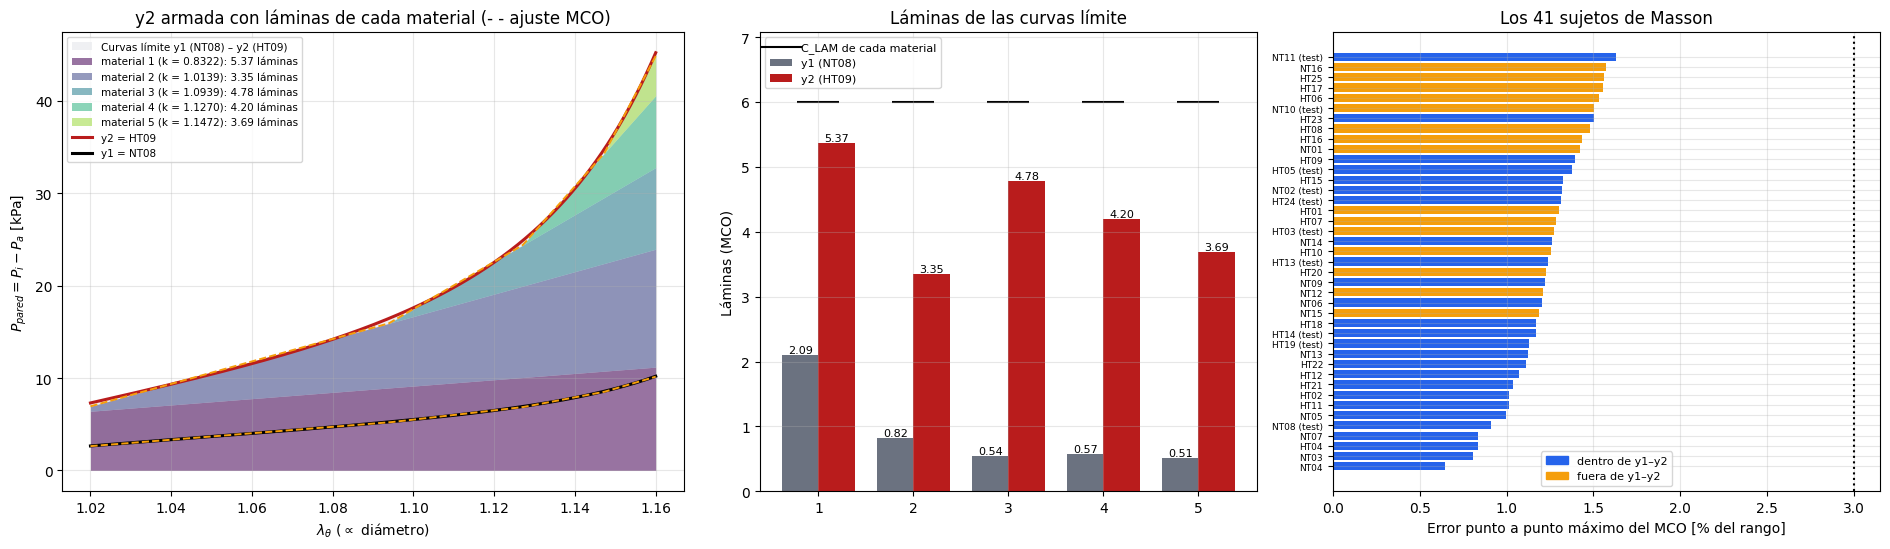

In [43]:
# CELDA 4: y2 ARMADA CON LÁMINAS, LÁMINAS DE LAS CURVAS LÍMITE Y ERROR DE LOS 41 SUJETOS
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

col = plt.cm.viridis(np.linspace(0.0, 0.85, len(NUDOS)))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1.1]))
banda(ax[0])
acum = np.cumsum(np.column_stack([np.zeros_like(X), A * C_Y2]), axis=1)
for j in range(len(NUDOS)):
    ax[0].fill_between(X, acum[:, j], acum[:, j + 1], color=col[j], alpha=0.55, lw=0,
                       label=f"material {j+1} (k = {NUDOS[j]:.4f}): {C_Y2[j]:.2f} láminas")
for y, c, cl, n in [(Y2, C_Y2, "#b91c1c", f"y2 = {SUJETO_Y2}"), (Y1, C_Y1, "k", f"y1 = {SUJETO_Y1}")]:
    ax[0].plot(X, y, color=cl, lw=2.2, label=n)
    ax[0].plot(X, A @ c, "--", color="#f59e0b", lw=1.4)
ax[0].set(xlabel=ETQ_X, ylabel=ETQ_Y, title="y2 armada con láminas de cada material (- - ajuste MCO)")
ax[0].legend(fontsize=7.5, loc="upper left")

i = np.arange(1, len(NUDOS) + 1)
for d, c, cl, n in [(-0.19, C_Y1, "#6b7280", f"y1 ({SUJETO_Y1})"), (0.19, C_Y2, "#b91c1c", f"y2 ({SUJETO_Y2})")]:
    ax[1].bar(i + d, c, 0.38, color=cl, label=n)
    for ii, v in zip(i, c):
        ax[1].text(ii + d, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax[1].scatter(i, C_LAM, marker="_", s=900, color="k", label="C_LAM de cada material")
ax[1].set(xticks=i, ylabel="Láminas (MCO)", ylim=(0, 1.18 * max(C_LAM.max(), C_Y2.max())), title="Láminas de las curvas límite")
ax[1].legend(fontsize=8, loc="upper left")

d = DF_PISO.sort_values("MaxAE_rel_pct")
ax[2].barh(range(len(d)), d.MaxAE_rel_pct, color=np.where(d.en_espacio, "#2563eb", "#f59e0b"))
ax[2].set_yticks(range(len(d)), [f"{n}{' (test)' if t else ''}" for n, t in zip(d.id, d.test)], fontsize=6.5)
ax[2].axvline(ERROR_MAX_PCT, color="k", ls=":")
ax[2].set(xlabel="Error punto a punto máximo del MCO [% del rango]", title="Los 41 sujetos de Masson")
ax[2].legend(handles=[Patch(color="#2563eb", label="dentro de y1–y2"), Patch(color="#f59e0b", label="fuera de y1–y2")], fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"laminas_curvas_limite_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 5 — Librerías, entrada logarítmica, métricas y predicción

In [44]:
# CELDA 5: LIBRERÍAS, TENSORFLOW, ENTRADA LOGARÍTMICA, MÉTRICAS, CONTROL DE CLASE Y PREDICCIÓN DE LA RED
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
from scipy.optimize import nnls

np.random.seed(SEED)
tf.random.set_seed(SEED)
OFFSET_LOG = float(max(0.0, -min(Y1.min(), POB_Y.min())) + 5.0)   # entrada de la red: log(y + OFFSET_LOG)


def entrada_log(Y):
    return np.log(np.maximum(np.asarray(Y) + OFFSET_LOG, 1e-6))


def metricas(Y, B):
    """R², RMSE, MaxAE [kPa], NRMSE y MaxAE_rel [% del rango de cada curva]; una curva o una por fila."""
    Y, E = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg, rmse, maxae = np.ptp(Y, axis=1), np.sqrt(np.mean(E ** 2, axis=1)), np.abs(E).max(axis=1)
    m = dict(R2=1 - np.sum(E ** 2, axis=1) / np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1),
             RMSE=rmse, MaxAE=maxae, NRMSE=rmse / rg * 100, MaxAE_rel=maxae / rg * 100)
    return {k: (float(v[0]) if len(v) == 1 else v) for k, v in m.items()}


def predecir(Y):
    """Láminas de cada material (diseño, C_LAM) que predice la red para una curva o una por fila."""
    c = sy.inverse_transform(model.predict(sx.transform(entrada_log(np.atleast_2d(Y))), batch_size=1024, verbose=0)) * ESC
    return c[0] if np.ndim(Y) == 1 else c


def panel(ax, s, titulo):
    """Curva de test #s: entrada, óptimo MCO y red (la usan las Celdas 12, 15 y 17)."""
    banda(ax)
    ax.plot(X, B_IN[s], "k-", lw=2, label="Curva de entrada")
    ax.plot(X, B_OPT[s], "b:", lw=1.8, label="Óptimo MCO")
    ax.plot(X, B_RN[s], "r--", lw=1.8, label="Red")
    ax.set_ylim(-0.03 * max(B_IN[s].max(), 1), 1.15 * max(B_IN[s].max(), 1))
    ax.set_title(titulo, fontsize=8.5, fontweight="bold")
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y)
    ax.grid(alpha=0.4, ls=":")
    ax.legend(fontsize=7, loc="upper left")


_K = np.linspace(NUDO_MIN_CLASE, X_MAX, N_NUDOS_CLASE + 2)[:-1]
_B_CLASE = np.maximum(0.0, X[:, None] - _K)[::3] / (X_MAX - _K)


def distancia_clase(y):
    """Distancia [% del rango] de y a las curvas realizables con capas (combinaciones c ≥ 0 de 40 líneas truncadas)."""
    ys = np.asarray(y)[::3]
    return float(np.sqrt(np.mean((ys - _B_CLASE @ nnls(_B_CLASE, ys)[0]) ** 2)) / np.ptp(y) * 100)


print(f"✅ TensorFlow {tf.__version__} ({'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}) | OFFSET_LOG = {OFFSET_LOG:g} | "
      f"control de clase: distancia ≤ {TOL_CLASE_NRMSE}%")

✅ TensorFlow 2.21.0 (CPU) | OFFSET_LOG = 5 | control de clase: distancia ≤ 2.0%


## Celda 6 — Dataset sintético

In [45]:
# CELDA 6: DATASET SINTÉTICO (etiqueta = MCO de la misma curva que ve la red, en láminas de la red)
#   0 pura: un material, láminas log-uniformes en [0,1; C_GEN_MAX_j]   1 combinada: 2–5 materiales, U(0, C_GEN_MAX_j)
#   2 constitutiva / 3 amplia / 5 uniforme: ley de Masson dentro de y1–y2   4 exponencial: otra ley   6 pacientes de entrenamiento
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

N_SAMPLES = 30000
FRAC = {0: 0.20, 1: 0.20, 2: 0.20, 4: 0.10, 6: 0.05, 5: 0.10}      # la amplia (3) completa el total
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial",
            5: "constitutiva_uniforme", 6: "pacientes"}
FAMILIAS_OBJETIVO = (2, 3, 4, 5, 6)
C_MIN_PURA, Y_TECHO = 0.10, 1.5 * float(POB_Y.max())
RUIDO_PURAS, RUIDO_CONST = 0.005, 0.01
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35)),
           4: dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]          # perturbación log-normal
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]   # en desvíos poblacionales
rng = np.random.default_rng(2026)
n = {f: int(round(v * N_SAMPLES)) for f, v in FRAC.items()}
n[3] = N_SAMPLES - sum(n.values())
nb = len(NUDOS)
ruido = lambda Y, r: np.maximum(Y + rng.normal(0.0, r, size=Y.shape) * np.abs(Y), 0.0)
LIMPIAS, RUIDOSAS, ACEPTACION = {}, {}, {}

# A) pura y B) combinada: curvas armadas con las bases (el orden de los sorteos reproduce el dataset de V21)
c0 = np.zeros((n[0], nb))
j0 = rng.permutation(np.arange(n[0]) % nb)
c0[np.arange(n[0]), j0] = np.exp(rng.uniform(np.log(C_MIN_PURA), np.log(C_GEN_MAX[j0])))
LIMPIAS[0] = c0 @ A_RED.T
RUIDOSAS[0] = ruido(LIMPIAS[0], RUIDO_PURAS)
c1 = np.zeros((n[1], nb))
for i in range(n[1]):
    act = rng.choice(nb, size=rng.integers(2, nb + 1), replace=False)
    c1[i, act] = rng.uniform(0.0, 1.0, size=len(act)) * C_GEN_MAX[act]
c1 *= np.minimum(1.0, Y_TECHO / np.maximum((c1 @ A_RED.T).max(axis=1, keepdims=True), 1e-9))
LIMPIAS[1] = c1 @ A_RED.T
RUIDOSAS[1] = ruido(LIMPIAS[1], RUIDO_PURAS)

# C) leyes constitutivas: mezcla convexa (Dirichlet) de sujetos de entrenamiento + perturbación + amplitud
TH = POB.loc[MASK_TRAIN, COLS_PARAM].to_numpy(float)
SD = POB[COLS_PARAM].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS_PARAM)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS_PARAM)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)       # módulos en escala log
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)
amplitud = lambda cfg: float(np.exp(rng.uniform(np.log(cfg["amp"][0]), np.log(cfg["amp"][1]))))


def ley_exp(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


def valida(y, acotar=True):
    return (np.all(np.isfinite(y)) and y.min() > 0 and y.max() <= Y_TECHO and all(diagnostico_forma(y))
            and (not acotar or bool(dentro_espacio(y)[0])))


def masson(th):
    return None if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2 else curva_objetivo(X, dict(zip(COLS_PARAM, th)))


def sortear(f):
    """Una curva de la familia f, o None si se rechaza."""
    if f == 5:                                                      # uniforme: parámetros independientes en [mín, máx]
        y = masson(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
        return y if y is not None and valida(y) else None
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    if f == 4:                                                      # exponencial: media geométrica de ajustes
        p = np.exp(w @ np.log(P_EXP[idx]) + rng.normal(0.0, cfg["sd_log"], size=4))
        y = amplitud(cfg) * ley_exp(X, *p)
        return y if valida(y, acotar=False) else None
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))     # γ > 1: extrapola desde el centro
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    y = masson(th)
    if y is None:
        return None
    y = amplitud(cfg) * y
    return y if valida(y) else None


P_EXP = np.maximum([curve_fit(ley_exp, X, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0), maxfev=40000,
                              bounds=([0, 0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]))[0] for y in POB_Y[MASK_TRAIN]], 1e-3)
for f in (2, 3, 4, 5):
    Y, intentos = [], 0
    while len(Y) < n[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), n[f] / intentos
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_CONST)
LIMPIAS[6] = POB_Y[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), n[6])]       # pacientes reales (sin recorte en 0)
RUIDOSAS[6] = LIMPIAS[6] + rng.normal(0.0, RUIDO_CONST, size=LIMPIAS[6].shape) * np.abs(LIMPIAS[6])

Y_limpio, Y_raw = (np.vstack([D[f] for f in sorted(FAMILIAS)]) for D in (LIMPIAS, RUIDOSAS))
familia = np.concatenate([np.full(n[f], f, np.int8) for f in sorted(FAMILIAS)])
C_RED = mco(Y_raw, A_RED)                                           # etiquetas (láminas de la red)
MASCARA = np.zeros_like(C_RED, dtype=np.float32)                    # crosstalk: materiales que el generador dejó en 0
MASCARA[:n[0] + n[1]] = np.vstack([c0, c1]) == 0
X_log = entrada_log(Y_raw)

_C0 = mco(Y_limpio, A)
_eM = err_pct(Y_limpio, _C0 @ A.T)[0]
print(f"✅ Dataset: {N_SAMPLES} curvas | etiquetas MCO en láminas")
print(pd.DataFrame({FAMILIAS[f]: {"curvas": n[f], "puntos fuera de y1–y2 %": 100 * np.mean((Y_raw[m] < Y1) | (Y_raw[m] > Y2)),
                                  "aceptación %": 100 * ACEPTACION.get(f, 1.0), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(_eM[m] <= ERROR_MAX_PCT),
                                  "error MCO máx. %": _eM[m].max(), "fabricables %": 100 * np.mean((C_RED[m] >= -1e-9).all(1))}
                    for f in FAMILIAS for m in [familia == f]}).T.round(2).to_string())
_esp = np.isin(familia, (2, 3, 5))
print(f"Espacio de trabajo ({_esp.sum()} curvas de Masson dentro de y1–y2): máximo de láminas por material "
      f"{_C0[_esp].max(0).round(2)} (C_LAM = {C_LAM})")

✅ Dataset: 30000 curvas | etiquetas MCO en láminas
                       curvas  puntos fuera de y1–y2 %  aceptación %  MCO cumple ≤3% %  error MCO máx. %  fabricables %
pura                   6000.0                    93.65        100.00             100.0              0.00           0.28
combinada              6000.0                    39.02        100.00             100.0              0.00          43.12
constitutiva           6000.0                     0.03         64.85             100.0              1.61         100.00
constitutiva_amplia    4500.0                     0.05         47.80             100.0              1.95          99.89
exponencial            3000.0                    16.49         99.57             100.0              2.77          99.53
constitutiva_uniforme  3000.0                     0.01         60.72             100.0              1.85         100.00
pacientes              1500.0                     9.98        100.00             100.0              1.57     

## Celda 7 — Partición y normalización

In [46]:
# CELDA 7: PARTICIÓN TRAIN / VAL / TEST (estratificada por familia) Y NORMALIZACIÓN
# Con ENTRENAR = False se usan los escaladores guardados con la red; deben coincidir con los de este dataset.
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_trval, idx_test = train_test_split(np.arange(N_SAMPLES), test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])
sx, sy = StandardScaler().fit(X_log[idx_train]), StandardScaler().fit(C_RED[idx_train])
if not ENTRENAR:
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    dif = max(np.abs(meta["scaler_x"].mean_ - sx.mean_).max(), np.abs(meta["scaler_y"].mean_ - sy.mean_).max())
    sx, sy = meta["scaler_x"], meta["scaler_y"]
    assert meta["offset_log"] == OFFSET_LOG, "OFFSET_LOG distinto del de la red guardada"
    print(f"📦 Escaladores de '{ARCHIVO_SCALERS}' | diferencia con este dataset: {dif:.1e} (≈ 0 ⇒ mismo dataset de entrenamiento)")
X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(C_RED[i]) for i in (idx_train, idx_val, idx_test))
m_train, m_val = MASCARA[idx_train], MASCARA[idx_val]
print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)} | sy.mean_ {sy.mean_.round(4)} | "
      f"sy.scale_ {sy.scale_.round(4)} | crosstalk penalizado en {MASCARA.mean():.1%} de los coeficientes")

c:\Users\Usuario\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


📦 Escaladores de 'scalers_curva_j_v22_5_c10.pkl' | diferencia con este dataset: 1.3e-15 (≈ 0 ⇒ mismo dataset de entrenamiento)
✅ Train 21000 | Val 3000 | Test 6000 | sy.mean_ [3.6107 3.2398 3.5547 3.3665 3.0742] | sy.scale_ [2.7541 2.5266 3.2032 3.0853 2.8795] | crosstalk penalizado en 22.1% de los coeficientes


## Celda 8 — Pérdida y arquitectura

In [47]:
# CELDA 8: PÉRDIDA Y ARQUITECTURA
# L = 1·MSE(láminas estandarizadas) + 5·MSE(A·ĉ − A·c, relativo al máximo de cada curva) + PESO_CROSSTALK·media(ĉ² en materiales ausentes)
import numpy as np
import tensorflow as tf

PESO_COEF, PESO_REC, PESO_CROSSTALK = 1.0, 5.0, 20.0     # crosstalk 20 (V21); V22 probó 5
CAPAS_OCULTAS, L2 = (256, 128, 64), 1e-5
nb = len(NUDOS)
_A_tf, _mu, _sd = (tf.constant(v, tf.float32) for v in (A_RED.T, sy.mean_, sy.scale_))


def perdida(y_aug, y_pred):
    y_true, mascara = y_aug[:, :nb], y_aug[:, nb:]                  # etiqueta | máscara de crosstalk
    c_true, c_pred = y_true * _sd + _mu, y_pred * _sd + _mu
    b_true, b_pred = c_true @ _A_tf, c_pred @ _A_tf
    y_max = tf.maximum(tf.reduce_max(b_true, axis=1, keepdims=True), 1.0)
    return (PESO_COEF * tf.reduce_mean(tf.square(y_true - y_pred))
            + PESO_REC * tf.reduce_mean(tf.square((b_true - b_pred) / (y_max + 1e-6)))
            + PESO_CROSSTALK * tf.reduce_mean(tf.square(c_pred) * mascara))


def mae(y_aug, y_pred):
    return tf.reduce_mean(tf.abs(y_aug[:, :nb] - y_pred))


capas = [tf.keras.Input(shape=(N_PTS,))]
for u in CAPAS_OCULTAS:
    capas += [tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(L2)),
              tf.keras.layers.LayerNormalization()]
model = tf.keras.Sequential(capas + [tf.keras.layers.Dense(nb)])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=perdida, metrics=[mae])
print(f"✅ Red {N_PTS} → {' → '.join(map(str, CAPAS_OCULTAS))} → {nb} (ReLU + LayerNormalization) | "
      f"{model.count_params():,} parámetros | pesos de la pérdida: {PESO_COEF:g} / {PESO_REC:g} / {PESO_CROSSTALK:g}")

✅ Red 999 → 256 → 128 → 64 → 5 (ReLU + LayerNormalization) | 298,373 parámetros | pesos de la pérdida: 1 / 5 / 20


## Celda 9 — Integridad de los datos

In [48]:
# CELDA 9: INTEGRIDAD DE LOS DATOS
import numpy as np

for k, v in dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test).items():
    assert np.isfinite(v).all(), f"{k} tiene NaN o Inf"
print(f"✅ Sin NaN ni Inf | etiquetas en [{C_RED.min():.3f}, {C_RED.max():.3f}] láminas | "
      f"curvas con algún c < 0: {np.mean(C_RED.min(1) < 0):.1%}")

✅ Sin NaN ni Inf | etiquetas en [-0.827, 23.012] láminas | curvas con algún c < 0: 32.2%


## Celda 10 — Entrenamiento o carga de la red

📦 Red cargada de 'modelo_rn_curva_j_v22_5_c10.keras' (sin reentrenar; 1782 épocas de entrenamiento)
   Pesos de la época 1702: val_loss 0.000817 | loss 0.000768 | convergencia práctica (≤ 1 % del mínimo) en la época 1703


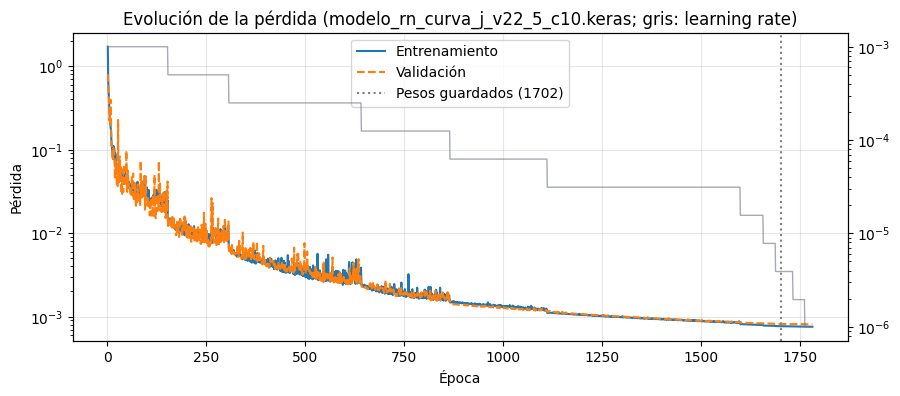

In [49]:
# CELDA 10: ENTRENAMIENTO (ENTRENAR = True) O CARGA DE LA RED ENTRENADA (False)
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import callbacks as cb
from tensorflow.keras.models import load_model

EPOCHS, BATCH_SIZE, MIN_DELTA = 2000, 64, 1e-5
if ENTRENAR:
    t0 = time.time()
    h = model.fit(X_train, np.hstack([y_train, m_train]), validation_data=(X_val, np.hstack([y_val, m_val])),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2,
                  callbacks=[cb.TerminateOnNaN(), cb.EarlyStopping(patience=80, min_delta=MIN_DELTA, restore_best_weights=True),
                             cb.ReduceLROnPlateau(factor=0.5, patience=30, min_delta=MIN_DELTA, min_lr=1e-6)])
    hist = pd.DataFrame(h.history, index=pd.RangeIndex(1, len(h.history["loss"]) + 1, name="epoca"))
    model.save(ARCHIVO_MODELO)
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump(dict(scaler_x=sx, scaler_y=sy, offset_log=OFFSET_LOG, c_lam_red=C_LAM_RED, nudos=NUDOS, version=VERSION), f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"✅ Entrenada en {(time.time() - t0) / 60:.1f} min ({len(hist)} épocas) → {ARCHIVO_MODELO}, {ARCHIVO_SCALERS}")
else:
    model = load_model(ARCHIVO_MODELO, compile=False)
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    print(f"📦 Red cargada de '{ARCHIVO_MODELO}' (sin reentrenar; {len(hist)} épocas de entrenamiento)")

v = hist["val_loss"].to_numpy()
mejor, ep = np.inf, len(v)                       # época que restaura EarlyStopping (última mejora > MIN_DELTA)
if len(v) < EPOCHS:
    for i, x_ in enumerate(v):
        if x_ + MIN_DELTA < mejor:
            mejor, ep = x_, i + 1
ep_conv = int(np.argmax(v <= v.min() * 1.01)) + 1
print(f"   Pesos de la época {ep}: val_loss {v[ep - 1]:.6f} | loss {hist['loss'].iloc[ep - 1]:.6f} | "
      f"convergencia práctica (≤ 1 % del mínimo) en la época {ep_conv}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(hist.index, hist["loss"], label="Entrenamiento")
ax.semilogy(hist.index, v, "--", label="Validación")
ax.axvline(ep, color="gray", ls=":", label=f"Pesos guardados ({ep})")
lr = next((c for c in ("learning_rate", "lr") if c in hist), None)
if lr:
    ax.twinx().semilogy(hist.index, hist[lr], color="#6b7280", lw=1, alpha=0.6)
ax.set(xlabel="Época", ylabel="Pérdida", title=f"Evolución de la pérdida ({ARCHIVO_MODELO}; gris: learning rate)")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 11 — Evaluación base en test

In [50]:
# CELDA 11: EVALUACIÓN BASE EN TEST (la usan las Celdas 12, 15 y 17)
# Todo en láminas del diseño (C_LAM). La red se evalúa sin pulido; el pulido en MCO es c = A⁺y (ecuaciones normales).
import time
import numpy as np

t0 = time.perf_counter()
C_RN = predecir(Y_raw[idx_test])
t_rn = (time.perf_counter() - t0) / len(idx_test)
C_OPT = C_RED[idx_test] * ESC                                     # etiqueta = MCO de la curva de entrada
FAM_T, B_IN, B_LIMPIO = familia[idx_test], Y_raw[idx_test], Y_limpio[idx_test]
B_RN, B_OPT = C_RN @ A.T, C_OPT @ A.T
t0 = time.perf_counter()
for y in B_IN[:300]:
    np.linalg.lstsq(A, y, rcond=None)
t_mco = (time.perf_counter() - t0) / 300
g = np.abs((A.T @ (B_OPT - B_IN).T)).max(0) / np.abs(A.T @ B_IN.T).max(0)
print(f"✅ Test: {len(idx_test)} curvas | láminas negativas: red {np.mean(C_RN.min(1) < 0):.1%} de las curvas "
      f"(mín. {C_RN.min():.3f}), MCO {np.mean(C_OPT.min(1) < 0):.1%} (mín. {C_OPT.min():.3f})")
print(f"   Pulido (MCO): ecuaciones normales |Aᵀ(Ac − y)| / |Aᵀy| ≤ {g.max():.1e} ⇒ red + pulido = óptimo exacto")
print(f"   Tiempo por curva: red en lote {t_rn * 1e3:.4f} ms | MCO {t_mco * 1e3:.4f} ms")

✅ Test: 6000 curvas | láminas negativas: red 25.8% de las curvas (mín. -0.375), MCO 32.4% (mín. -0.491)
   Pulido (MCO): ecuaciones normales |Aᵀ(Ac − y)| / |Aᵀy| ≤ 2.3e-15 ⇒ red + pulido = óptimo exacto
   Tiempo por curva: red en lote 0.2307 ms | MCO 0.0675 ms


## Celda 12 — Reconstrucción en test (una muestra por familia)

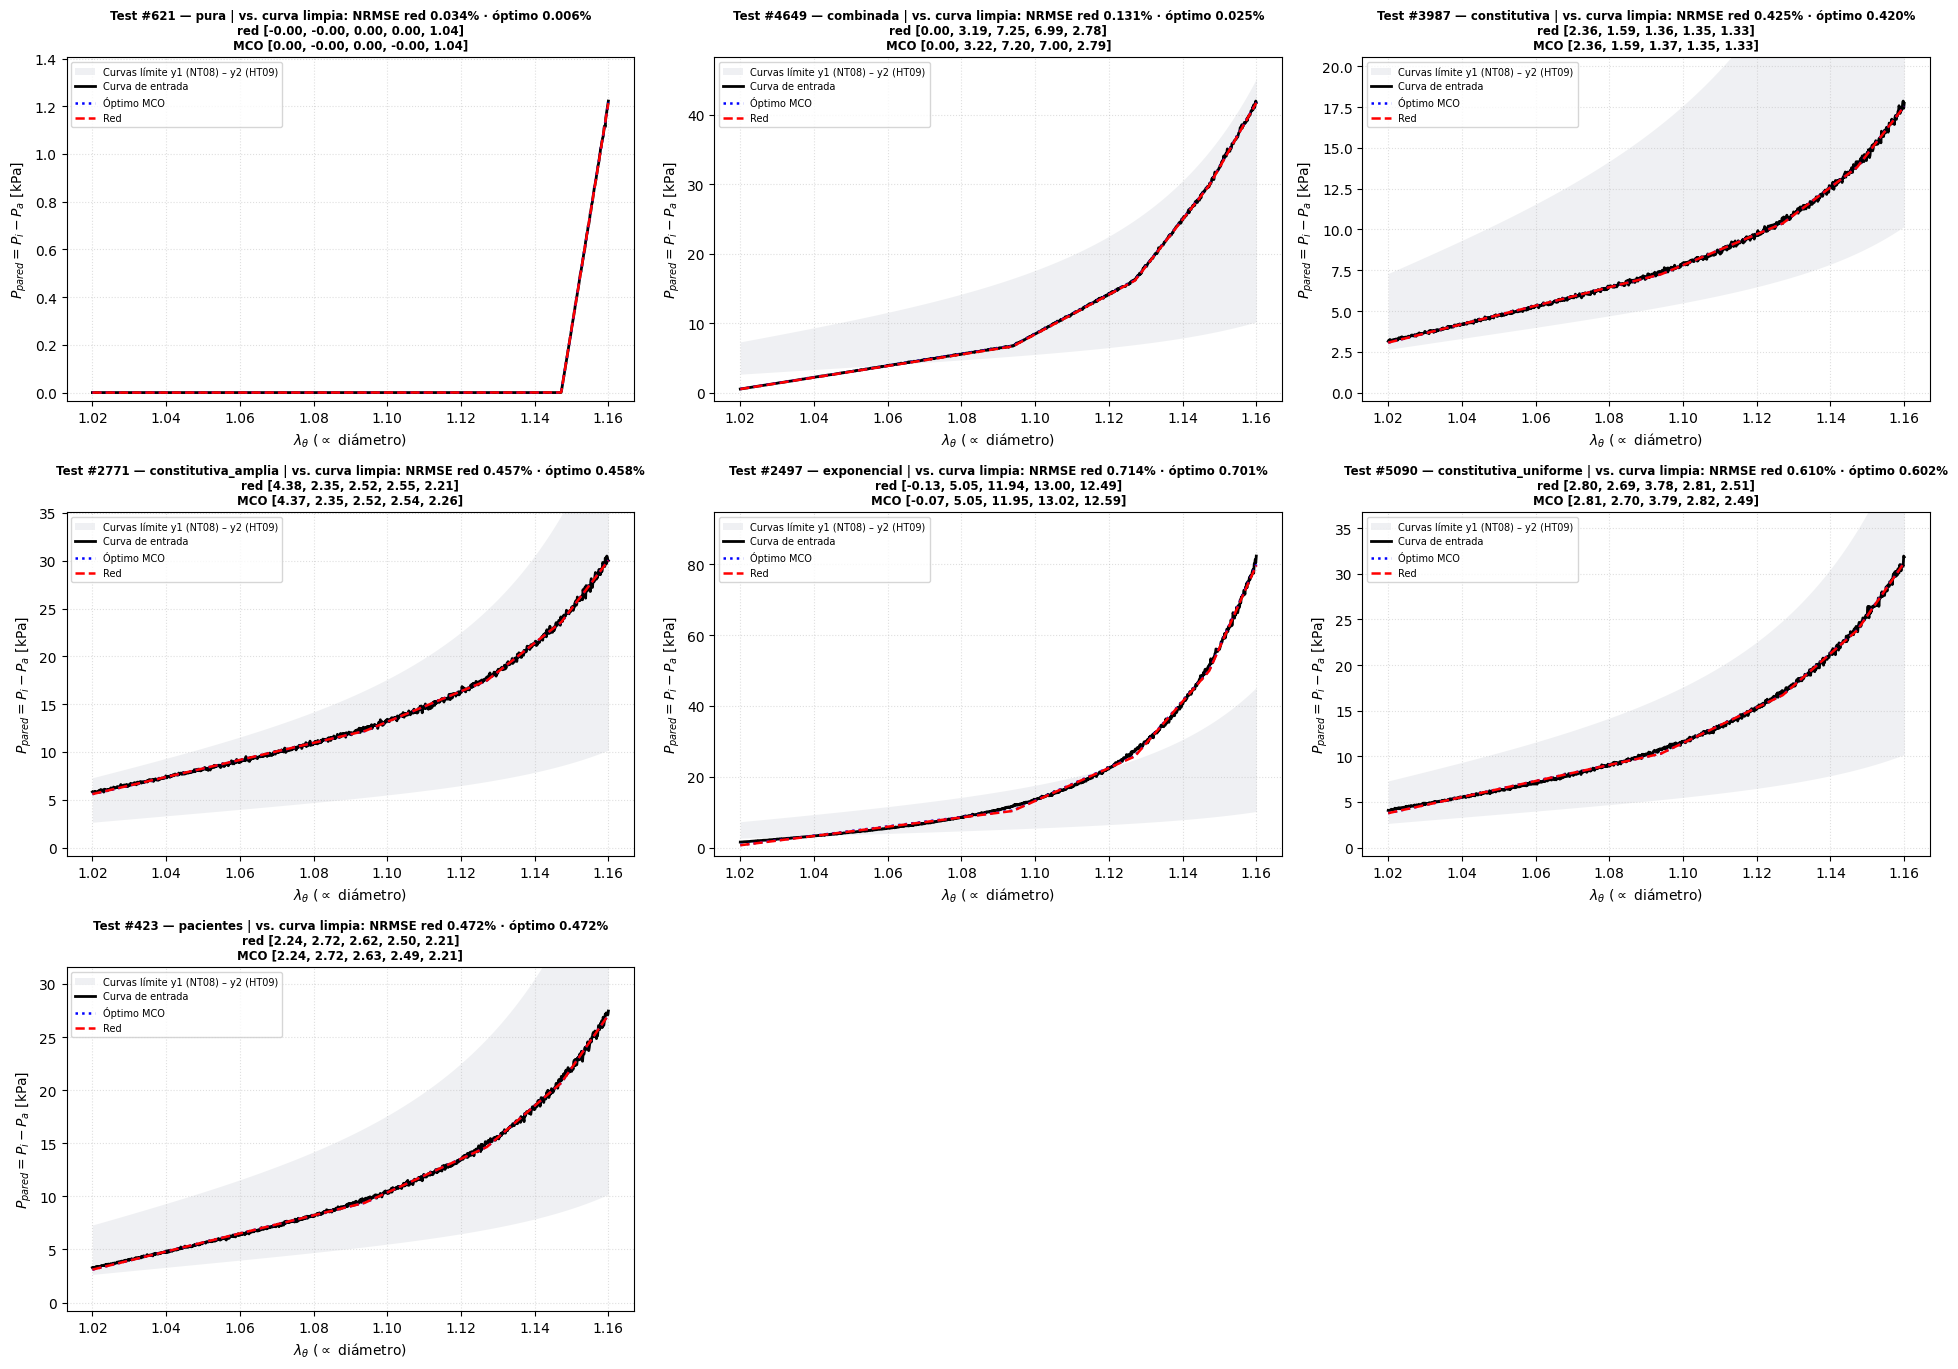

NRMSE medio [%] por familia:
                       red vs. limpia  óptimo vs. limpia  red vs. entrada con ruido
pura                            0.388              0.028                      0.589
combinada                       0.261              0.023                      0.394
constitutiva                    0.447              0.440                      0.747
constitutiva_amplia             0.455              0.436                      0.762
exponencial                     0.533              0.501                      0.763
constitutiva_uniforme           0.458              0.443                      0.785
pacientes                       0.479              0.465                      0.756


In [51]:
# CELDA 12: RECONSTRUCCIÓN EN TEST (una muestra por familia) Y ERROR CONTRA LA CURVA SIN RUIDO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(19.5, 13.8))
for ax, f in zip(axes.flat, sorted(FAMILIAS)):
    s = int(rng_plot.choice(np.where(FAM_T == f)[0]))
    mr, mo = metricas(B_LIMPIO[s], B_RN[s]), metricas(B_LIMPIO[s], B_OPT[s])
    panel(ax, s, f"Test #{s} — {FAMILIAS[f]} | vs. curva limpia: NRMSE red {mr['NRMSE']:.3f}% · óptimo {mo['NRMSE']:.3f}%\n"
                 f"red [{', '.join(f'{v:.2f}' for v in C_RN[s])}]\nMCO [{', '.join(f'{v:.2f}' for v in C_OPT[s])}]")
for ax in axes.flat[len(FAMILIAS):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"reconstruccion_curvas_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

M0_RN, M0_OPT, MI_RN = metricas(B_LIMPIO, B_RN), metricas(B_LIMPIO, B_OPT), metricas(B_IN, B_RN)
print("NRMSE medio [%] por familia:")
print(pd.DataFrame({FAMILIAS[f]: {"red vs. limpia": M0_RN["NRMSE"][m].mean(), "óptimo vs. limpia": M0_OPT["NRMSE"][m].mean(),
                                  "red vs. entrada con ruido": MI_RN["NRMSE"][m].mean()}
                    for f in FAMILIAS for m in [FAM_T == f]}).T.round(3).to_string())

## Celda 13 — Validación con los 41 sujetos y las 4 curvas medias

In [52]:
# CELDA 13: VALIDACIÓN CON LOS 41 SUJETOS REALES Y LAS 4 CURVAS MEDIAS (red vs. óptimo MCO, sin ruido)
import numpy as np
import pandas as pd

C_SUJ_RN, C_SUJ_OPT = predecir(POB_Y), mco(POB_Y)
MS_RN, MS_OPT = metricas(POB_Y, C_SUJ_RN @ A.T), metricas(POB_Y, C_SUJ_OPT @ A.T)
DF_SUJ = POB[["id", "grupo", "test"]].assign(R2_red=MS_RN["R2"], R2_opt=MS_OPT["R2"], NRMSE_red=MS_RN["NRMSE"],
                                             NRMSE_opt=MS_OPT["NRMSE"], MaxAE_rel_red=MS_RN["MaxAE_rel"],
                                             dc_max=np.abs(C_SUJ_RN - C_SUJ_OPT).max(1),
                                             en_clase=[distancia_clase(y) <= TOL_CLASE_NRMSE for y in POB_Y])
DF_SUJ["exceso_pct"] = (DF_SUJ.NRMSE_red / DF_SUJ.NRMSE_opt - 1) * 100
DF_SUJ.to_csv(f"validacion_sujetos_reales_{VERSION}.csv", index=False)
print(pd.DataFrame({k: {"n": m.sum(), "R² red mín.": DF_SUJ.R2_red[m].min(), "NRMSE óptimo %": DF_SUJ.NRMSE_opt[m].mean(),
                        "NRMSE red %": DF_SUJ.NRMSE_red[m].mean(),
                        "exceso %": (DF_SUJ.NRMSE_red[m].mean() / DF_SUJ.NRMSE_opt[m].mean() - 1) * 100,
                        "error pto. red máx. %": DF_SUJ.MaxAE_rel_red[m].max(),
                        f"red cumple ≤{ERROR_MAX_PCT:g}%": (DF_SUJ.MaxAE_rel_red[m] <= ERROR_MAX_PCT).sum(), "máx |Δc|": DF_SUJ.dc_max[m].max()}
                    for k, m in {"Test": DF_SUJ.test, "Entrenamiento": ~DF_SUJ.test, "NT": DF_SUJ.grupo == "NT",
                                 "HT": DF_SUJ.grupo == "HT", "Todos": DF_SUJ.id.notna()}.items()}).T.round(4).to_string())
_t = DF_SUJ[DF_SUJ.test]
print(f"Peor R² de la red: {DF_SUJ.id[DF_SUJ.R2_red.idxmin()]} | exceso en test: mediana {_t.exceso_pct.median():+.1f}%, "
      f"máximo {_t.exceso_pct.max():+.1f}% ({_t.id[_t.exceso_pct.idxmax()]}) | control de clase: {DF_SUJ.en_clase.mean():.0%} aceptados")

RES_MEDIAS = {}
for k, y in MEDIAS.items():
    c_rn, c_opt = predecir(y), mco(y)
    RES_MEDIAS[k] = dict(y=y, b_rn=A @ c_rn, b_opt=A @ c_opt, m_rn=metricas(y, A @ c_rn), m_opt=metricas(y, A @ c_opt))
    print(f"\n{k} (n = {GRUPOS_MEDIAS[k].sum()}): láminas MCO {c_opt.round(4)} (total {c_opt.sum():.2f}) | red {c_rn.round(4)}")
    print(f"   NRMSE red {RES_MEDIAS[k]['m_rn']['NRMSE']:.4f}% / óptimo {RES_MEDIAS[k]['m_opt']['NRMSE']:.4f}% | "
          f"error pto. red {RES_MEDIAS[k]['m_rn']['MaxAE_rel']:.3f}% / óptimo {RES_MEDIAS[k]['m_opt']['MaxAE_rel']:.3f}% | "
          f"exceso de RMSE {(RES_MEDIAS[k]['m_rn']['RMSE'] / RES_MEDIAS[k]['m_opt']['RMSE'] - 1) * 100:+.2f}%")

                  n  R² red mín.  NRMSE óptimo %  NRMSE red %  exceso %  error pto. red máx. %  red cumple ≤3%  máx |Δc|
Test           10.0       0.9993          0.4950       0.5026    1.5306                 1.6300            10.0    0.0450
Entrenamiento  31.0       0.9989          0.4583       0.4723    3.0475                 1.5956            31.0    0.1165
NT             16.0       0.9993          0.4375       0.4405    0.6814                 1.6300            16.0    0.0450
HT             25.0       0.9989          0.4863       0.5047    3.7922                 1.5956            25.0    0.1165
Todos          41.0       0.9989          0.4673       0.4797    2.6555                 1.6300            41.0    0.1165
Peor R² de la red: HT10 | exceso en test: mediana +0.5%, máximo +6.6% (HT13) | control de clase: 100% aceptados

Mean Young (n = 7): láminas MCO [3.2582 1.8318 1.4114 1.411  1.2839] (total 9.20) | red [3.261  1.8324 1.4151 1.4091 1.2909]
   NRMSE red 0.3758% / óptimo 0.3725

## Celda 14 — Figuras: curvas medias y sujetos de test

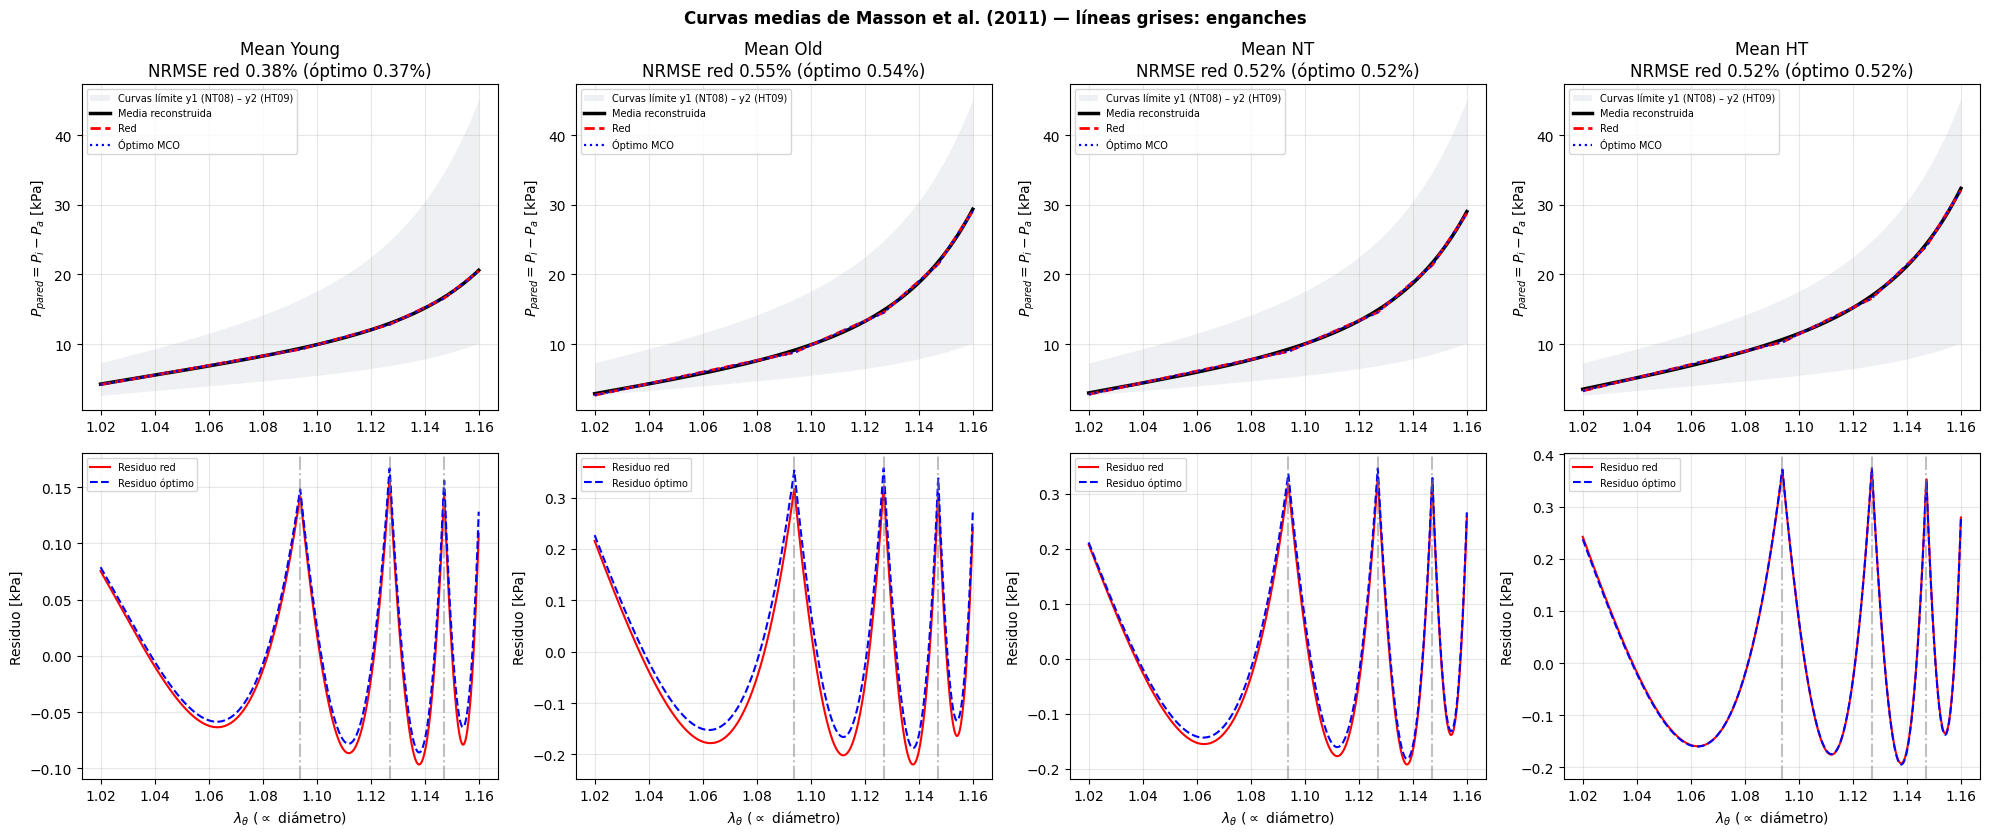

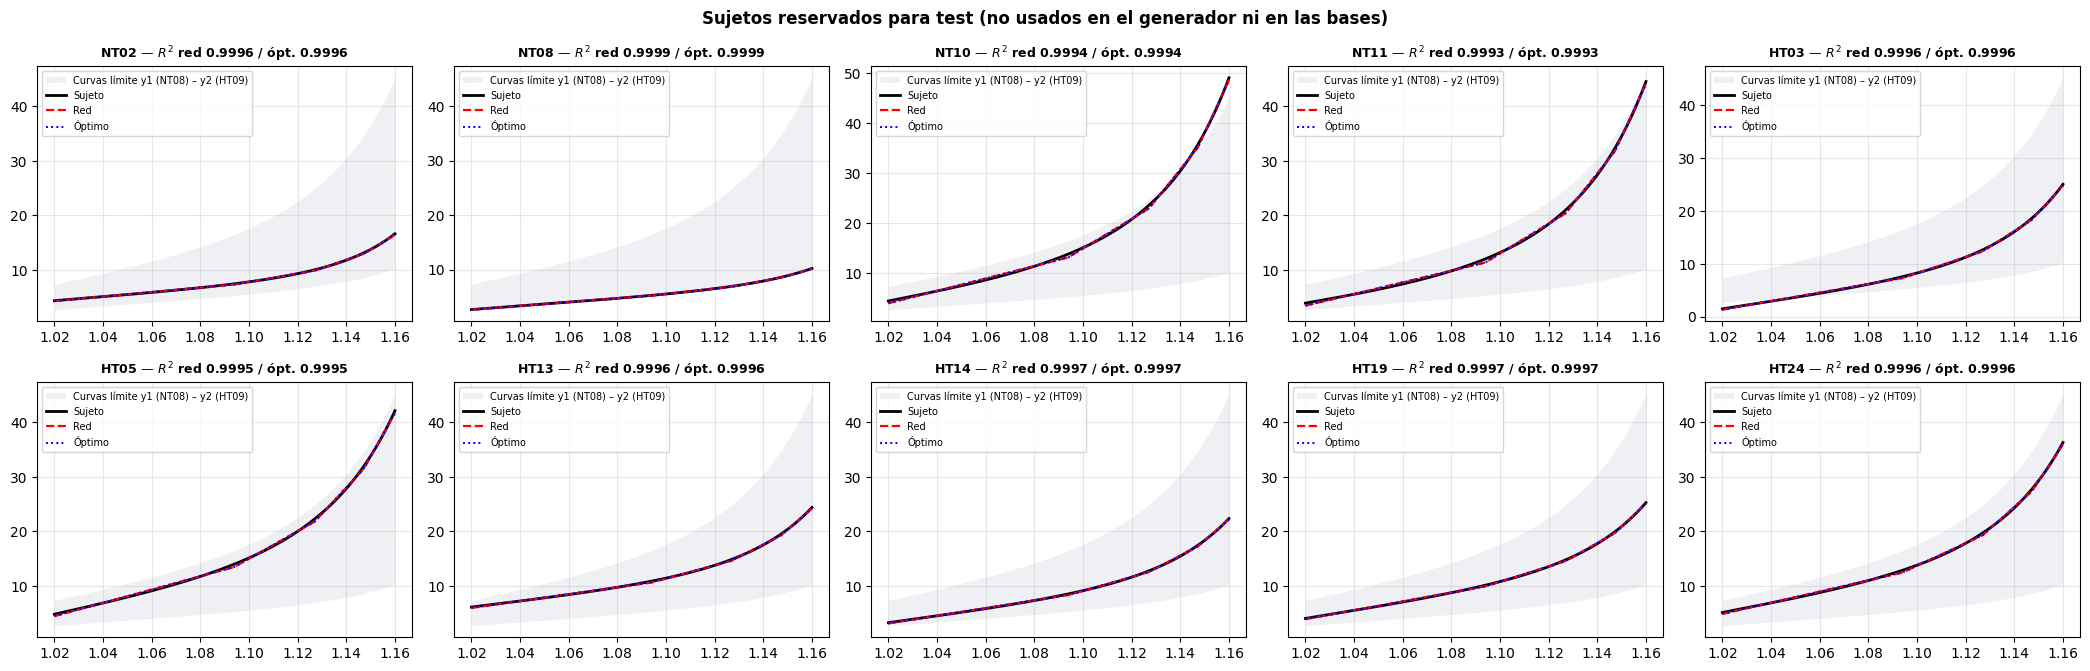

In [53]:
# CELDA 14: FIGURAS DE VALIDACIÓN — CURVAS MEDIAS (con residuos) Y SUJETOS DE TEST
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for (k, r), a, b in zip(RES_MEDIAS.items(), axes[0], axes[1]):
    banda(a)
    a.plot(X, r["y"], "k-", lw=2.5, label="Media reconstruida")
    a.plot(X, r["b_rn"], "r--", lw=2, label="Red")
    a.plot(X, r["b_opt"], "b:", lw=1.6, label="Óptimo MCO")
    a.set(title=f"{k}\nNRMSE red {r['m_rn']['NRMSE']:.2f}% (óptimo {r['m_opt']['NRMSE']:.2f}%)", ylabel=ETQ_Y)
    a.legend(fontsize=7, loc="upper left")
    b.plot(X, r["y"] - r["b_rn"], "r-", lw=1.5, label="Residuo red")
    b.plot(X, r["y"] - r["b_opt"], "b--", lw=1.5, label="Residuo óptimo")
    for k_ in NUDOS[NUDOS >= X_MIN]:
        b.axvline(k_, color="gray", ls="-.", alpha=0.5)
    b.set(xlabel=ETQ_X, ylabel="Residuo [kPa]")
    b.legend(fontsize=7)
for a in axes.flat:
    a.grid(alpha=0.3)
plt.suptitle("Curvas medias de Masson et al. (2011) — líneas grises: enganches", fontweight="bold")
plt.tight_layout()
plt.savefig(f"validacion_curvas_medias_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(21, 6.8))
for ax, i in zip(axes.flat, np.where(MASK_TEST)[0]):
    banda(ax)
    ax.plot(X, POB_Y[i], "k-", lw=2, label="Sujeto")
    ax.plot(X, A @ C_SUJ_RN[i], "r--", lw=1.6, label="Red")
    ax.plot(X, A @ C_SUJ_OPT[i], "b:", lw=1.4, label="Óptimo")
    ax.set_title(f"{POB.id[i]} — $R^2$ red {MS_RN['R2'][i]:.4f} / ópt. {MS_OPT['R2'][i]:.4f}", fontsize=9, fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
plt.suptitle("Sujetos reservados para test (no usados en el generador ni en las bases)", fontweight="bold")
plt.tight_layout()
plt.savefig(f"validacion_sujetos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 15 — Evaluación en test por familia, criterio y peores casos

Láminas, todas las familias (n = 6000): R² [0.999947 0.999956 0.999903 0.999889 0.999753] | MAE [0.0066 0.0055 0.0104 0.0113 0.0164]
Láminas, familias fisiológicas (n = 3600): R² [0.999926 0.999936 0.99987  0.99987  0.999749] | MAE [0.0061 0.0051 0.0096 0.0103 0.0141]

Reconstrucción contra la curva de entrada; criterio contra la curva sin ruido. Exceso = NRMSE red / NRMSE óptimo − 1.
                            n  NRMSE óptimo %  NRMSE red %  exceso %  R² red mín.  peor (test #)  red cumple ≤3% %  red máx. %  MCO cumple ≤3% %  MCO máx. %
pura                   1200.0           0.347        0.589    69.618        0.895         5734.0            94.667      13.964             100.0       0.756
combinada              1200.0           0.259        0.394    51.898        0.954         2737.0            98.417       8.427             100.0       0.398
constitutiva           1200.0           0.743        0.747     0.500        0.997         2594.0           100.000       2.182             10

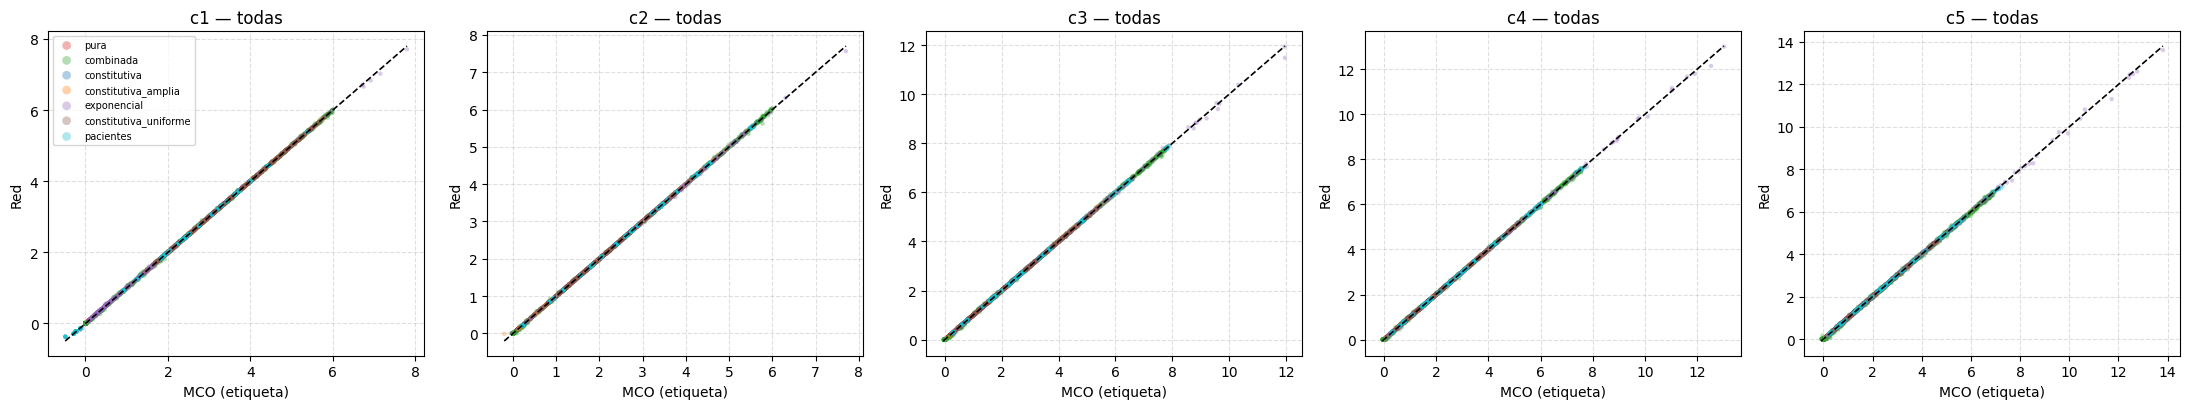

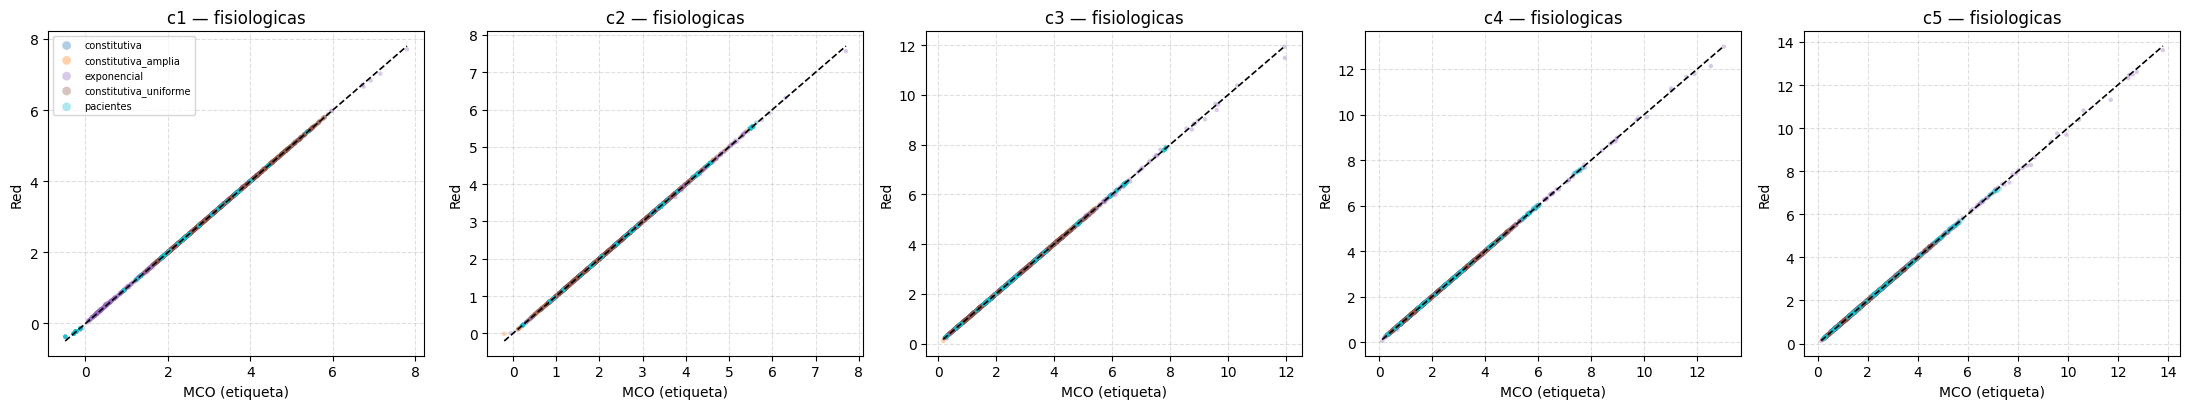

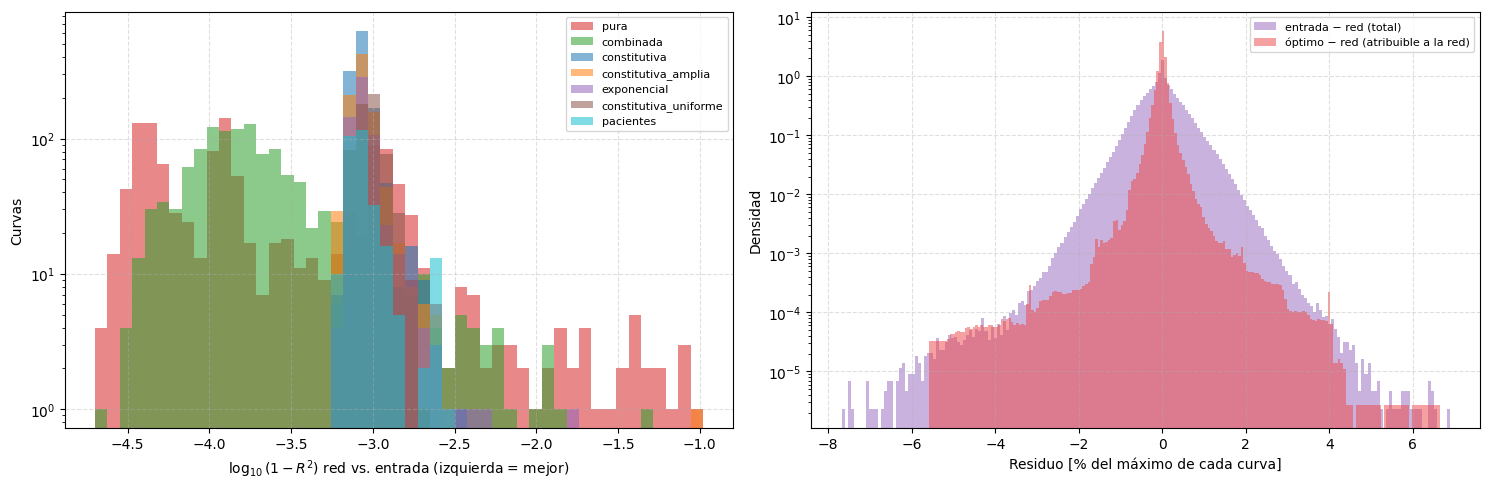

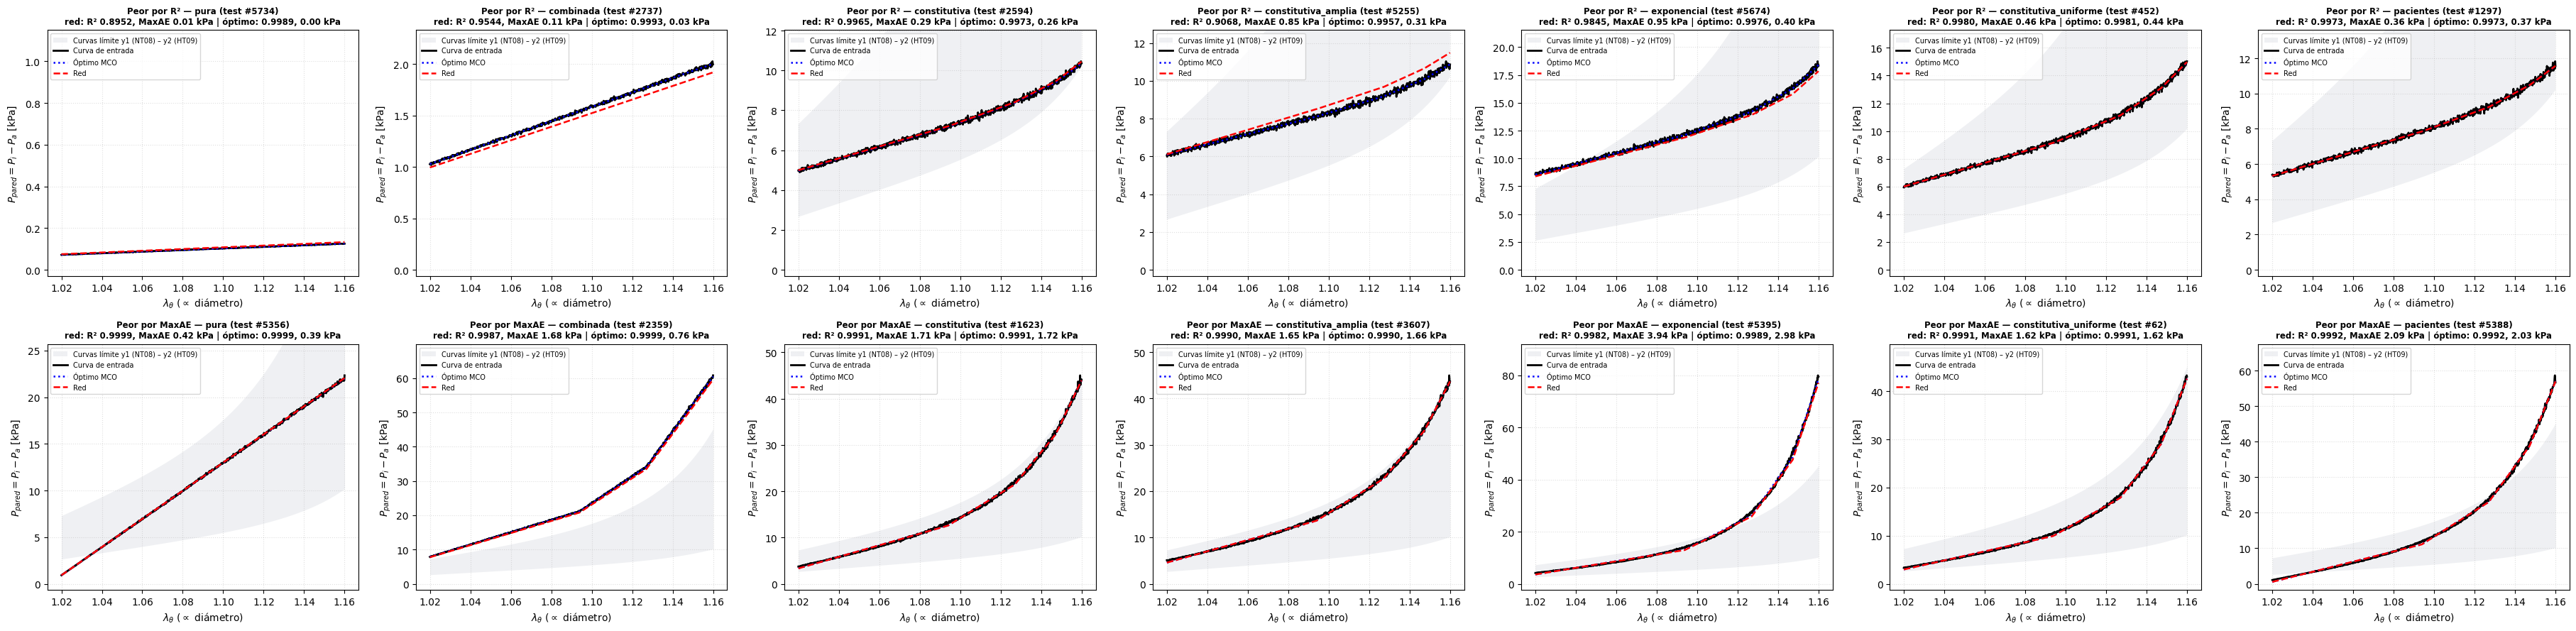

In [54]:
# CELDA 15: EVALUACIÓN EN TEST — LÁMINAS, EXCESO DE LA RED SOBRE EL ÓPTIMO, CRITERIO Y PEORES CASOS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

M_RN, M_OPT = metricas(B_IN, B_RN), metricas(B_IN, B_OPT)
E0_RN, E0_OPT = metricas(B_LIMPIO, B_RN)["MaxAE_rel"], metricas(B_LIMPIO, B_OPT)["MaxAE_rel"]
fisio = np.isin(FAM_T, FAMILIAS_OBJETIVO)
for titulo, m in [("todas las familias", np.ones_like(fisio)), ("familias fisiológicas", fisio)]:
    d = C_RN[m] - C_OPT[m]
    print(f"Láminas, {titulo} (n = {m.sum()}): R² {np.round(1 - (d ** 2).sum(0) / ((C_OPT[m] - C_OPT[m].mean(0)) ** 2).sum(0), 6)} | "
          f"MAE {np.abs(d).mean(0).round(4)}")

RESUMEN = pd.DataFrame({FAMILIAS[f]: {"n": m.sum(), "NRMSE óptimo %": M_OPT["NRMSE"][m].mean(), "NRMSE red %": M_RN["NRMSE"][m].mean(),
                                      "exceso %": (M_RN["NRMSE"][m].mean() / M_OPT["NRMSE"][m].mean() - 1) * 100,
                                      "R² red mín.": M_RN["R2"][m].min(), "peor (test #)": int(np.where(m)[0][np.argmin(M_RN["R2"][m])]),
                                      f"red cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(E0_RN[m] <= ERROR_MAX_PCT),
                                      "red máx. %": E0_RN[m].max(), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(E0_OPT[m] <= ERROR_MAX_PCT),
                                      "MCO máx. %": E0_OPT[m].max()} for f in FAMILIAS for m in [FAM_T == f]}).T
print("\nReconstrucción contra la curva de entrada; criterio contra la curva sin ruido. Exceso = NRMSE red / NRMSE óptimo − 1.")
print(RESUMEN.round(3).to_string())
RESUMEN.to_csv(f"resumen_test_por_familia_{VERSION}.csv")
pd.DataFrame(np.column_stack([idx_test, FAM_T, M_RN["NRMSE"], M_OPT["NRMSE"], E0_RN, C_OPT, C_RN]),
             columns=["idx", "familia", "NRMSE_red", "NRMSE_opt", "MaxAE_rel_red_limpia"]
             + [f"c{j+1}_{t}" for t in ("mco", "red") for j in range(len(NUDOS))]).to_csv(f"metricas_test_por_curva_{VERSION}.csv", index=False)

COL = dict(zip(sorted(FAMILIAS), ["#d62728", "#2ca02c", "#1f77b4", "#ff7f0e", "#9467bd", "#8c564b", "#17becf"]))
for nombre, fams in [("todas", sorted(FAMILIAS)), ("fisiologicas", FAMILIAS_OBJETIVO)]:
    fig, axes = plt.subplots(1, len(NUDOS), figsize=(4.4 * len(NUDOS), 4.2))
    for j, ax in enumerate(axes):
        for f in fams:
            m = FAM_T == f
            ax.scatter(C_OPT[m, j], C_RN[m, j], s=10, alpha=0.35, color=COL[f], edgecolors="none", label=FAMILIAS[f])
        lim = [C_OPT[np.isin(FAM_T, fams), j].min(), C_OPT[np.isin(FAM_T, fams), j].max()]
        ax.plot(lim, lim, "k--", lw=1.2)
        ax.set(title=f"c{j+1} — {nombre}", xlabel="MCO (etiqueta)", ylabel="Red")
        ax.grid(alpha=0.4, ls="--")
    axes[0].legend(fontsize=7, markerscale=2)
    plt.tight_layout()
    plt.savefig(f"diagnostico_coeficientes_{nombre}_{VERSION}.png", dpi=300, bbox_inches="tight")
    plt.show()

ymax = np.maximum(B_IN.max(1, keepdims=True), 1.0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
le = np.log10(np.clip(1 - M_RN["R2"], 1e-8, None))
for f in FAMILIAS:
    a1.hist(le[FAM_T == f], bins=np.linspace(le.min(), le.max(), 50), alpha=0.55, color=COL[f], label=FAMILIAS[f])
a1.set(yscale="log", xlabel=r"$\log_{10}(1 - R^2)$ red vs. entrada (izquierda = mejor)", ylabel="Curvas")
for d, c, n in [((B_IN - B_RN) / ymax * 100, "#9467bd", "entrada − red (total)"), ((B_OPT - B_RN) / ymax * 100, "#ef4444", "óptimo − red (atribuible a la red)")]:
    a2.hist(d.ravel(), bins=200, density=True, alpha=0.5, color=c, label=n)
a2.set(yscale="log", xlabel="Residuo [% del máximo de cada curva]", ylabel="Densidad")
for a in (a1, a2):
    a.legend(fontsize=8)
    a.grid(alpha=0.4, ls="--")
plt.tight_layout()
plt.savefig(f"distribucion_residuos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 9))
for c, f in enumerate(FAMILIAS):
    m = np.where(FAM_T == f)[0]
    for r, (s, crit) in enumerate([(m[np.argmin(M_RN["R2"][m])], "R²"), (m[np.argmax(M_RN["MaxAE"][m])], "MaxAE")]):
        panel(axes[r, c], s, f"Peor por {crit} — {FAMILIAS[f]} (test #{s})\nred: R² {M_RN['R2'][s]:.4f}, MaxAE {M_RN['MaxAE'][s]:.2f} kPa"
                             f" | óptimo: {M_OPT['R2'][s]:.4f}, {M_OPT['MaxAE'][s]:.2f} kPa")
plt.tight_layout()
plt.savefig(f"peores_casos_test_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 16 — Ley de Fung (nunca vista) y control de clase

In [55]:
# CELDA 16: GENERALIZACIÓN A UNA LEY NUNCA VISTA (Fung) Y CONTROL DE CLASE A LA ENTRADA
#   Fung: P = C + A·(exp(B·(λ − λ_min)) − 1), parámetros mezclados de los ajustes a sujetos de entrenamiento.
#   Control de clase: debe aceptar curvas J (Fung, sujetos) y rechazar sujetos de test modulados con una oscilación.
import numpy as np
from scipy.optimize import curve_fit

N_OOD, RUIDO_OOD = 300, 0.01
rng_ood = np.random.default_rng(2027)
fung = lambda x, a, b, c: c + a * (np.exp(b * (x - X_MIN)) - 1.0)
P_FUNG = np.array([curve_fit(fung, X, y, p0=(5.0, 20.0, max(float(y[0]), 0.01)), bounds=([1e-6, 1e-3, 0], [1e4, 200, 1e3]),
                             maxfev=20000)[0] for y in POB_Y[MASK_TRAIN]])
Y_fung = []
while len(Y_fung) < N_OOD:
    k = rng_ood.integers(2, 4)
    idx = rng_ood.choice(len(P_FUNG), size=k, replace=False)
    y = fung(X, *np.exp(rng_ood.dirichlet(np.ones(k)) @ np.log(P_FUNG[idx]) + rng_ood.normal(0.0, 0.10, size=3)))
    if y.min() > 0 and y.max() <= Y_TECHO:
        Y_fung.append(y)
Y_fung = np.array(Y_fung)
Y_fung_r = np.maximum(Y_fung + rng_ood.normal(0.0, RUIDO_OOD, size=Y_fung.shape) * np.abs(Y_fung), 0.0)
Mf_rn, Mf_opt = metricas(Y_fung_r, predecir(Y_fung_r) @ A.T), metricas(Y_fung_r, mco(Y_fung_r) @ A.T)
i = int(np.argmin(Mf_rn["R2"]))
print(f"🧪 Fung ({N_OOD} curvas, ruido 1 %, {np.mean((Y_fung < Y1) | (Y_fung > Y2)):.1%} de puntos fuera de y1–y2): "
      f"NRMSE red {Mf_rn['NRMSE'].mean():.3f}% | óptimo {Mf_opt['NRMSE'].mean():.3f}% | "
      f"exceso {(Mf_rn['NRMSE'].mean() / Mf_opt['NRMSE'].mean() - 1) * 100:+.1f}% | peor R² red {Mf_rn['R2'][i]:.5f} "
      f"(óptimo {Mf_opt['R2'][i]:.5f}) | MCO fabricable {np.mean((mco(Y_fung_r) >= 0).all(1)):.1%}")

t = X - X_MIN
Y_mod = []
for y in POB_Y[MASK_TEST]:
    for _ in range(max(1, N_OOD // (4 * MASK_TEST.sum()))):
        f, a = rng_ood.uniform(1.0, 3.0), rng_ood.uniform(0.10, 0.30)
        Y_mod.append(y * (1.0 + a * np.sin(2 * np.pi * f * t / t[-1] + rng_ood.uniform(0, 2 * np.pi))))
Y_mod = np.array(Y_mod)
Y_mod_r = np.maximum(Y_mod + rng_ood.normal(0.0, RUIDO_OOD, size=Y_mod.shape) * np.abs(Y_mod), 0.0)
no_J = np.array([not all(diagnostico_forma(y)) for y in Y_mod])
acepta = lambda Y: np.array([distancia_clase(y) <= TOL_CLASE_NRMSE for y in Y])
a_mod = acepta(Y_mod_r)
print(f"🛂 Control de clase (≤ {TOL_CLASE_NRMSE}%): acepta {acepta(Y_fung_r).mean():.1%} de las Fung y {acepta(POB_Y).mean():.0%} "
      f"de los sujetos | rechaza {(~a_mod[no_J]).mean():.1%} de las moduladas fuera de la clase (n = {no_J.sum()}); "
      f"acepta {a_mod[~no_J].mean():.1%} de las que siguieron siendo J (n = {(~no_J).sum()})")

🧪 Fung (300 curvas, ruido 1 %, 7.8% de puntos fuera de y1–y2): NRMSE red 1.146% | óptimo 1.117% | exceso +2.6% | peor R² red 0.99620 (óptimo 0.99734) | MCO fabricable 99.7%
🛂 Control de clase (≤ 2.0%): acepta 100.0% de las Fung y 100% de los sujetos | rechaza 95.7% de las moduladas fuera de la clase (n = 47); acepta 73.9% de las que siguieron siendo J (n = 23)


## Celda 17 — Muestras aleatorias de test

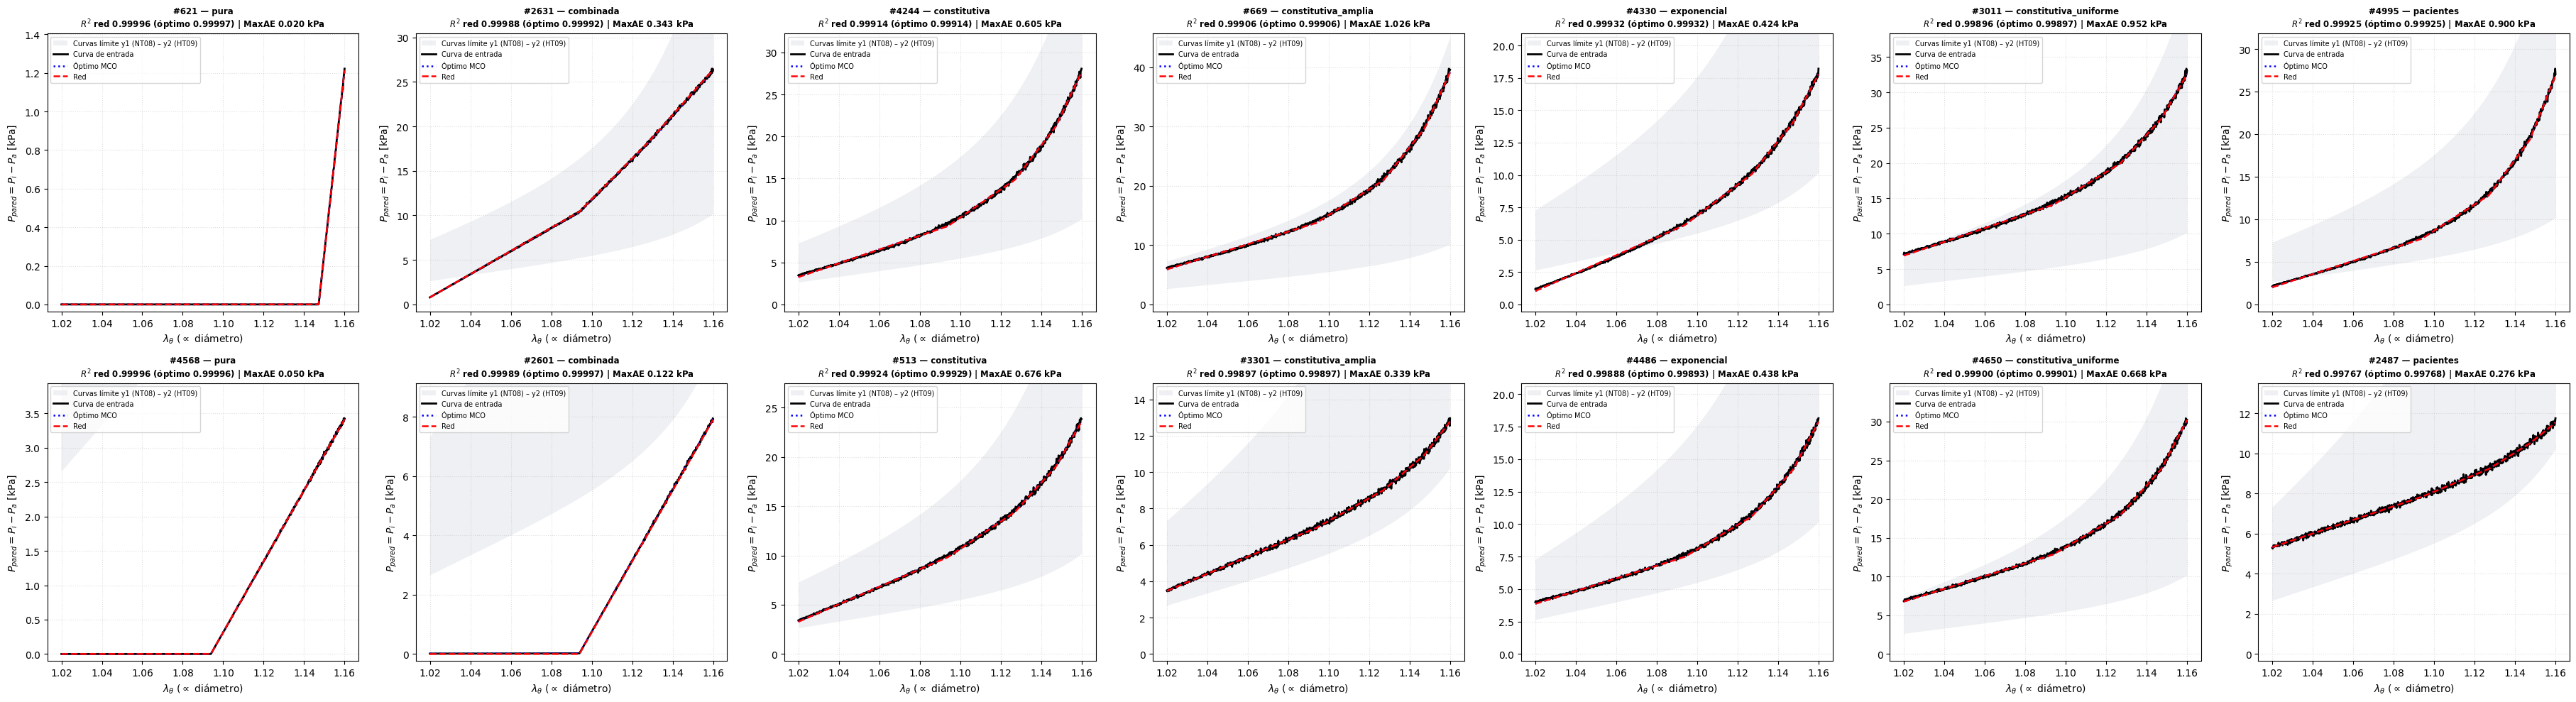

In [56]:
# CELDA 17: MUESTRAS ALEATORIAS DE TEST (2 por familia; escala vertical por panel)
import numpy as np
import matplotlib.pyplot as plt

rng_plot = np.random.default_rng(SEED)
muestras = [rng_plot.choice(np.where(FAM_T == f)[0], size=2, replace=False) for f in sorted(FAMILIAS)]
fig, axes = plt.subplots(2, len(FAMILIAS), figsize=(5.2 * len(FAMILIAS), 10))
for c, (f, ss) in enumerate(zip(sorted(FAMILIAS), muestras)):
    for r, s in enumerate(ss):
        panel(axes[r, c], s, f"#{s} — {FAMILIAS[f]}\n$R^2$ red {M_RN['R2'][s]:.5f} (óptimo {M_OPT['R2'][s]:.5f}) | "
                             f"MaxAE {M_RN['MaxAE'][s]:.3f} kPa")
plt.tight_layout()
plt.savefig(f"reconstruccion_ejemplos_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 18 — Diseñador de injerto

🫀 Mean HT | curva J: sí | dentro de y1–y2: True | fabricable (c ≥ 0): True
              MCO      red  diferencia
material                              
1         2.34522  2.34057    -0.00465
2         3.05875  3.06361     0.00486
3         3.42255  3.41641    -0.00614
4         3.18930  3.18706    -0.00224
5         2.85629  2.86063     0.00434
Total de láminas: MCO 14.872 | red 14.868
           R2      RMSE     MaxAE     NRMSE  MaxAE_rel
MCO  0.999579  0.148928  0.373329  0.516280   1.294199
red  0.999579  0.148945  0.373396  0.516339   1.294429

🧵 Injerto: radio de reposo = 0.8322·R_ref = 2.85 mm (R_ref = 3.42 mm), sin pretensado | P en λ = 1.16: 32.09 kPa (241 mmHg)
          enganche λ  holgura de fibra [%]  láminas c  C_LAM  K de 1 lámina [N/m]  E (t=0.1 mm) [MPa]  K total [N/m]  aporte P λ=1.16 [kPa]  deform. máx. [%]
material                                                                                                                                                     
1   

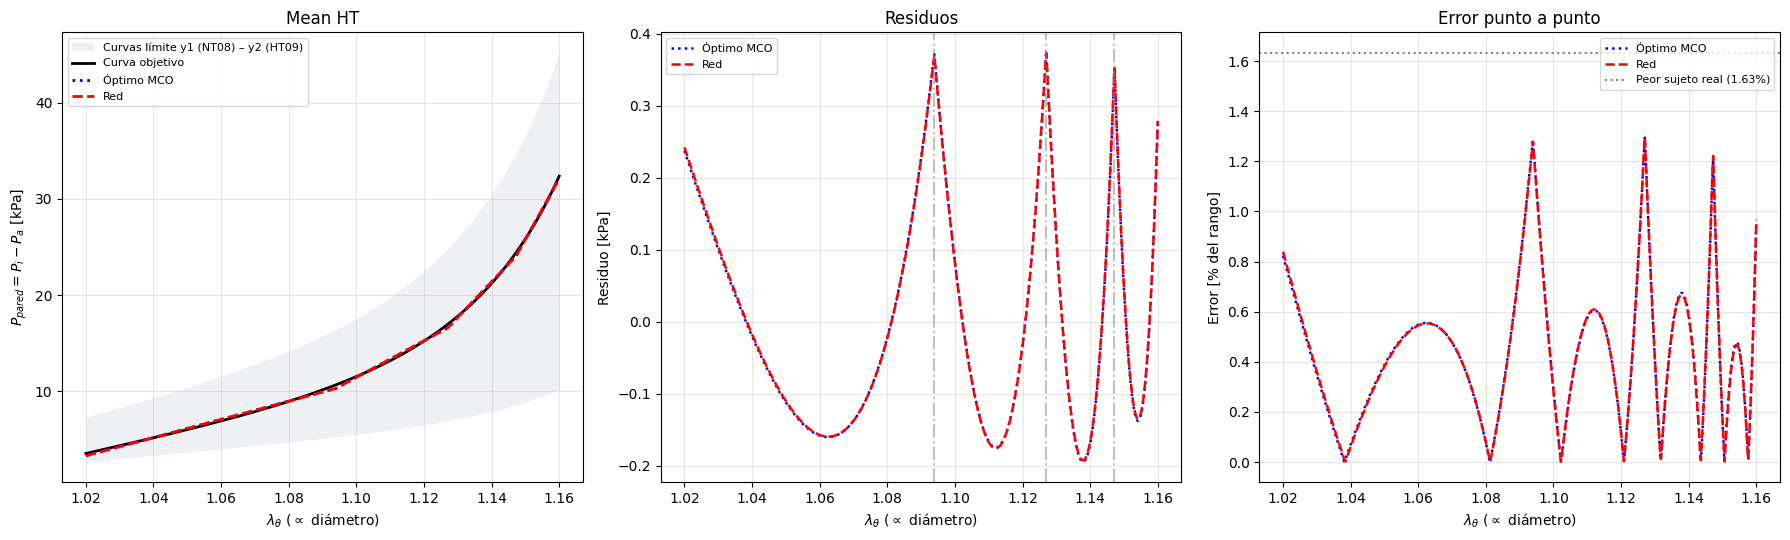

In [57]:
# CELDA 18: DISEÑADOR DE INJERTO — curva presión–diámetro → láminas de cada material
#   MODO = "masson": un sujeto ("HT07") o una curva media ("Mean HT") | "excel": columnas (λθ, P [kPa]) | "puntos": PUNTOS
#   Resultado del método: MCO exacto (red + pulido si la curva es J; MCO directo si no). La red sola se muestra para comparar.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

MODO, SUJETO_EVAL = "masson", "Mean HT"
ARCHIVO_CURVA = "Curva_J.xlsx"
PUNTOS = [(1.07, 7.0), (1.10, 12.0), (1.13, 20.0), (1.16, 36.0)]     # (λθ, P_pared [kPa]), interpolación PCHIP

if MODO == "masson":
    y_t = MEDIAS[SUJETO_EVAL] if SUJETO_EVAL in MEDIAS else POB_Y[(POB.id == SUJETO_EVAL).to_numpy()][0]
    R_suj = R_REF if SUJETO_EVAL in MEDIAS else float(np.deg2rad(POB.Theta0_deg[POB.id == SUJETO_EVAL]).iloc[0]
                                                      * POB.Rm_mm[POB.id == SUJETO_EVAL].iloc[0] / np.pi)
else:
    xu, yu = (np.array(PUNTOS, float).T if MODO == "puntos" else pd.read_excel(ARCHIVO_CURVA, header=None).to_numpy(float)[:, :2].T)
    o = np.argsort(xu)
    y_t = PchipInterpolator(xu[o], yu[o], extrapolate=False)(X) if MODO == "puntos" else np.interp(X, xu[o], yu[o])
    y_t, R_suj = np.where(np.isnan(y_t), np.interp(X, xu[o], yu[o]), y_t), R_REF
en_clase = distancia_clase(y_t) <= TOL_CLASE_NRMSE
c_opt, c_rn = mco(y_t), predecir(y_t)
m_opt, m_rn = metricas(y_t, A @ c_opt), metricas(y_t, A @ c_rn)
print(f"🫀 {SUJETO_EVAL if MODO == 'masson' else MODO} | curva J: {'sí' if en_clase else 'NO (resultado = MCO directo)'} | "
      f"dentro de y1–y2: {bool(dentro_espacio(y_t)[0])} | fabricable (c ≥ 0): {bool((c_opt >= 0).all())}")
print(pd.DataFrame({"MCO": c_opt, "red": c_rn, "diferencia": c_rn - c_opt}, index=pd.Index(range(1, len(NUDOS) + 1), name="material"))
      .round(5).to_string())
print(f"Total de láminas: MCO {c_opt.sum():.3f} | red {c_rn.sum():.3f}")
print(pd.DataFrame({"MCO": m_opt, "red": m_rn}).T.round(6).to_string())

DISENO = pd.DataFrame({"enganche λ": NUDOS, "holgura de fibra [%]": (NUDOS / NUDOS[0] - 1) * 100, "láminas c": c_opt,
                       "C_LAM": C_LAM, "K de 1 lámina [N/m]": S * R_suj * NUDOS ** 2,
                       f"E (t={ESPESOR_LAMINA_MM:g} mm) [MPa]": S * R_suj * NUDOS ** 2 / ESPESOR_LAMINA_MM * 1e-3,
                       "K total [N/m]": c_opt * S * R_suj * NUDOS ** 2, f"aporte P λ={X_MAX:g} [kPa]": c_opt * A[-1],
                       "deform. máx. [%]": (X_MAX / NUDOS - 1) * 100}, index=pd.Index(range(1, len(NUDOS) + 1), name="material"))
print(f"\n🧵 Injerto: radio de reposo = {NUDOS[0]:.4f}·R_ref = {NUDOS[0] * R_suj:.2f} mm (R_ref = {R_suj:.2f} mm), sin pretensado | "
      f"P en λ = {X_MAX:g}: {A[-1] @ c_opt:.2f} kPa ({A[-1] @ c_opt / 0.133322:.0f} mmHg)")
print(DISENO.round(4).to_string())
DISENO.to_csv(f"diseno_injerto_{VERSION}.csv")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
banda(ax[0])
for b, st, n in [(y_t, "k-", "Curva objetivo"), (A @ c_opt, "b:", "Óptimo MCO"), (A @ c_rn, "r--", "Red")]:
    ax[0].plot(X, b, st, lw=2, label=n)
    if n != "Curva objetivo":
        ax[1].plot(X, y_t - b, st, lw=1.8, label=n)
        ax[2].plot(X, np.abs(y_t - b) / np.ptp(y_t) * 100, st, lw=1.8, label=n)
for k_ in NUDOS[NUDOS >= X_MIN]:
    ax[1].axvline(k_, color="gray", ls="-.", alpha=0.5)
ax[2].axhline(PISO_MAXAE, color="gray", ls=":", label=f"Peor sujeto real ({PISO_MAXAE:.2f}%)")
for a, yl, ti in zip(ax, [ETQ_Y, "Residuo [kPa]", "Error [% del rango]"], [SUJETO_EVAL, "Residuos", "Error punto a punto"]):
    a.set(xlabel=ETQ_X, ylabel=yl, title=ti)
    a.legend(fontsize=8)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"evaluacion_inferencia_curva_j_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 19 — Reproducción de láminas aisladas

 material  láminas a  R2_red  error c activo %  crosstalk máx.
        1       0.25 0.99906           0.52028         0.00088
        1       0.50 0.99991          -0.05347         0.00067
        1       1.00 0.99975           0.30972         0.00061
        1       2.00 0.99999          -0.01708         0.00076
        1       4.00 0.99996           0.07592         0.00097
        2       0.25 0.99995          -0.42236         0.00102
        2       0.50 1.00000           0.07333         0.00078
        2       1.00 0.99987           0.52312         0.00026
        2       2.00 1.00000          -0.10336         0.00071
        2       4.00 1.00000          -0.11060         0.00043
        3       0.25 0.99999           0.22444         0.00054
        3       0.50 1.00000          -0.20972         0.00117
        3       1.00 1.00000           0.03796         0.00040
        3       2.00 1.00000          -0.22761         0.00060
        3       4.00 0.99999          -0.22524         

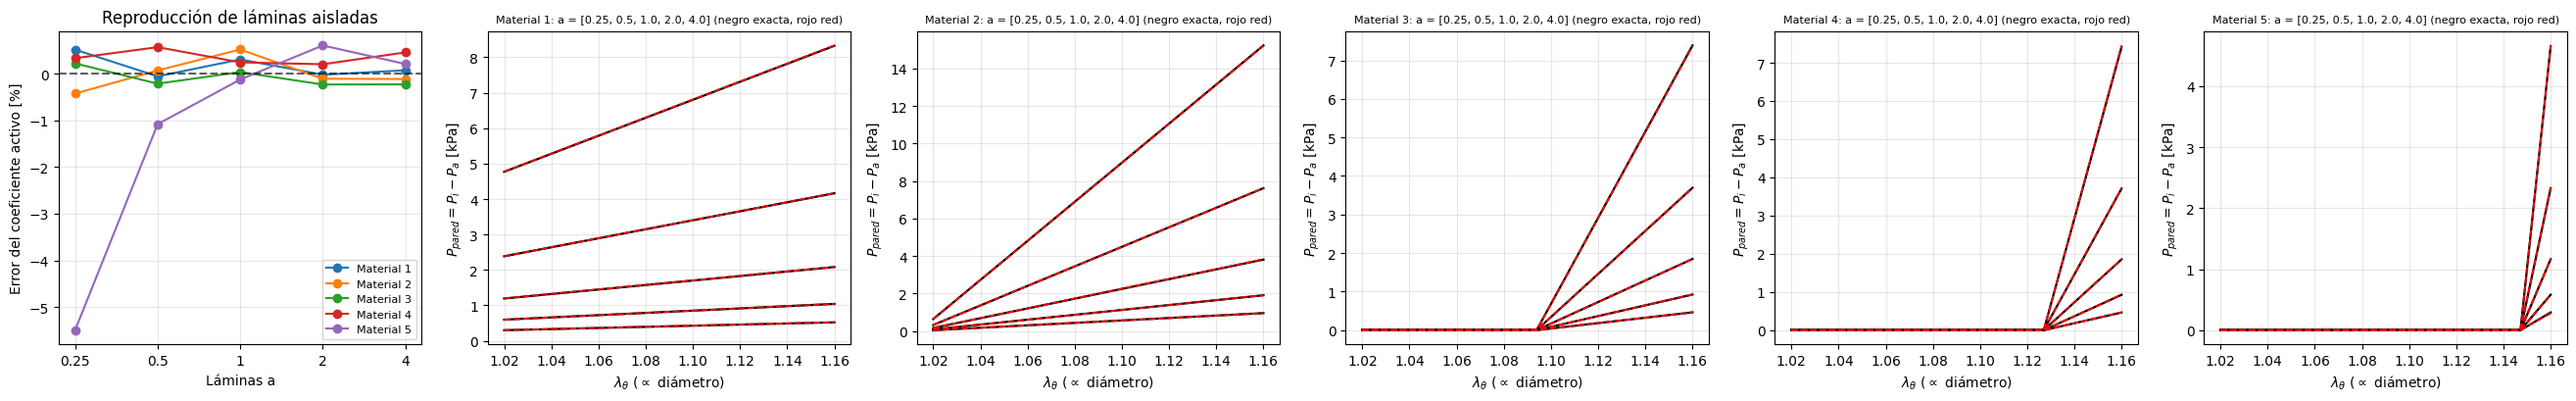

In [58]:
# CELDA 19: REPRODUCCIÓN DE LÁMINAS AISLADAS (entrada y = a·A_j; respuesta exacta c = a·e_j)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AMPLITUDES = [0.25, 0.5, 1.0, 2.0, 4.0]                              # láminas del diseño
nb = len(NUDOS)
C_EX = np.vstack([a * np.eye(nb)[j] for j in range(nb) for a in AMPLITUDES])
Y_B = C_EX @ A.T
C_B = predecir(Y_B)
j_act = np.repeat(np.arange(nb), len(AMPLITUDES))
act = C_B[np.arange(len(C_B)), j_act]
DF_B = pd.DataFrame({"material": j_act + 1, "láminas a": np.tile(AMPLITUDES, nb), "R2_red": metricas(Y_B, C_B @ A.T)["R2"],
                     "error c activo %": (act / C_EX.max(1) - 1) * 100,
                     "crosstalk máx.": np.abs(np.where(C_EX > 0, 0.0, C_B)).max(1)})
print(DF_B.round(5).to_string(index=False))
print(f"Peor |error| del coeficiente activo: {DF_B['error c activo %'].abs().max():.3f}% | crosstalk máx.: {DF_B['crosstalk máx.'].max():.5f} láminas")
DF_B.to_csv(f"test_reproduccion_bases_{VERSION}.csv", index=False)

fig, ax = plt.subplots(1, nb + 1, figsize=(4.4 * (nb + 1), 4.2))
for j in range(nb):
    d = DF_B[DF_B.material == j + 1]
    ax[0].plot(d["láminas a"], d["error c activo %"], "o-", label=f"Material {j+1}")
    m = j_act == j
    ax[j + 1].plot(X, Y_B[m].T, "k-", lw=1.6)
    ax[j + 1].plot(X, (C_B[m] @ A.T).T, "r--", lw=1.3)
    ax[j + 1].set(title=f"Material {j+1}: a = {AMPLITUDES} (negro exacta, rojo red)", xlabel=ETQ_X, ylabel=ETQ_Y)
ax[0].axhline(0, color="k", ls="--", alpha=0.6)
ax[0].set(xscale="log", xlabel="Láminas a", ylabel="Error del coeficiente activo [%]", title="Reproducción de láminas aisladas")
ax[0].set_xticks(AMPLITUDES, [f"{a:g}" for a in AMPLITUDES])
ax[0].minorticks_off()
ax[0].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
for a in ax[1:]:
    a.title.set_fontsize(8)
plt.tight_layout()
plt.savefig(f"test_reproduccion_bases_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 20 — Las bases con su fórmula

Fórmulas verificadas contra las bases: |diferencia| máx. = 0.0e+00 kPa
   A_1(λ) = 6,35·max(0, λ − 0,8322)
   A_2(λ) = 26,07·max(0, λ − 1,0139)
   A_3(λ) = 27,93·max(0, λ − 1,0939)
   A_4(λ) = 56,18·max(0, λ − 1,1270)
   A_5(λ) = 90,98·max(0, λ − 1,1472)


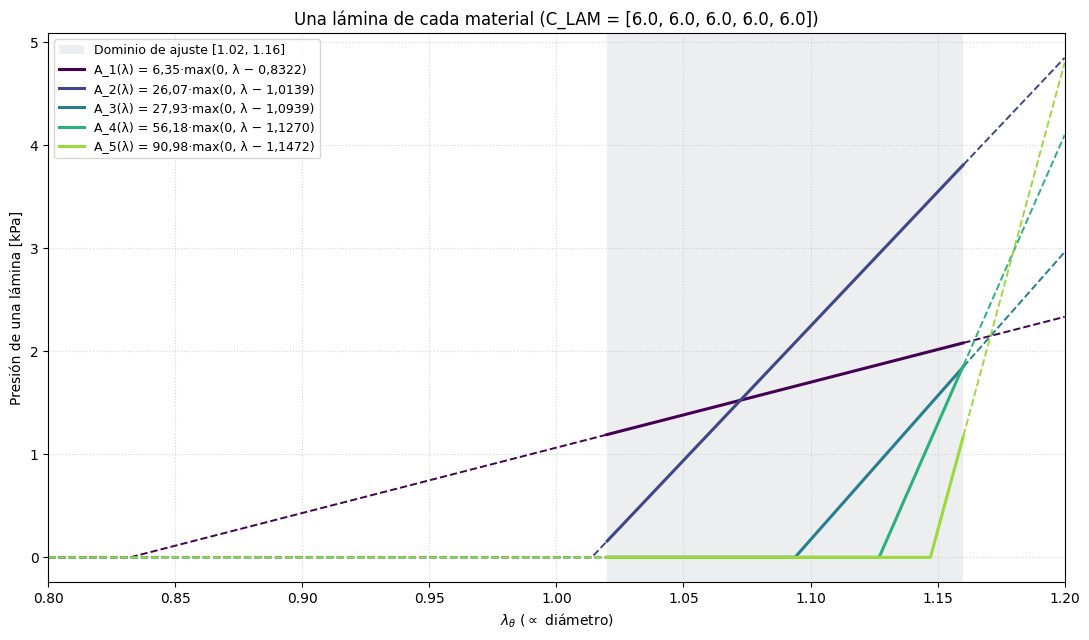

In [59]:
# CELDA 20: LAS BASES CON SU FÓRMULA (continua: dominio de ajuste; punteada: extensión de la misma fórmula)
import numpy as np
import matplotlib.pyplot as plt

LAMBDA_GRAF = (0.80, 1.20)                                           # rango del gráfico (p. ej. (0.0, 1.2))
lam = np.linspace(*LAMBDA_GRAF, 2401)
Ab = np.maximum(0.0, lam[:, None] - NUDOS) * S
dentro = (lam >= X_MIN) & (lam <= X_MAX)
print(f"Fórmulas verificadas contra las bases: |diferencia| máx. = {np.abs(np.maximum(0, X[:, None] - NUDOS) * S - A).max():.1e} kPa")
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axvspan(X_MIN, X_MAX, color="#e5e7eb", alpha=0.7, lw=0, label=f"Dominio de ajuste [{X_MIN}, {X_MAX}]")
for j, c in enumerate(plt.cm.viridis(np.linspace(0, 0.85, len(NUDOS)))):
    f = f"A_{j+1}(λ) = {S[j]:.2f}·max(0, λ − {NUDOS[j]:.4f})".replace(".", ",")
    print("   " + f)
    ax.plot(lam, np.where(dentro, Ab[:, j], np.nan), color=c, lw=2.2, label=f)
    ax.plot(lam, np.where(dentro, np.nan, Ab[:, j]), color=c, lw=1.4, ls="--")
ax.set(xlim=LAMBDA_GRAF, xlabel=ETQ_X, ylabel="Presión de una lámina [kPa]",
       title=f"Una lámina de cada material (C_LAM = {C_LAM.tolist()})")
ax.grid(alpha=0.5, ls=":")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(f"bases_funcionales_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

## Celda 21 — Extrapolación fuera del dominio de ajuste

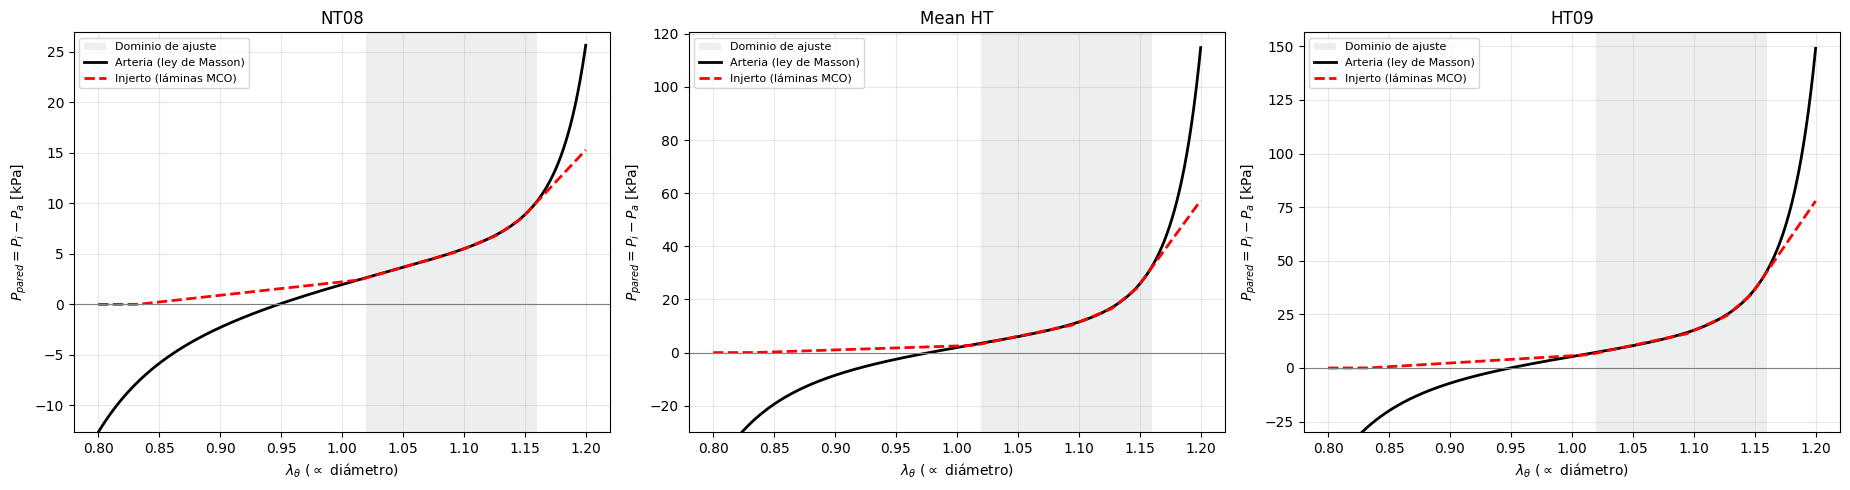

                                        NT08       Mean HT          HT09
λ=0.8: arteria / injerto [kPa]   -12.7 / 0.0   -45.2 / 0.0   -50.2 / 0.0
λ=0.9: arteria / injerto [kPa]    -2.3 / 0.9    -8.5 / 1.0    -7.1 / 2.3
λ=0.95: arteria / injerto [kPa]    0.1 / 1.6    -2.5 / 1.8     0.1 / 4.0
λ=1: arteria / injerto [kPa]       2.0 / 2.2     1.9 / 2.5     5.3 / 5.7
λ=1.18: arteria / injerto [kPa]  14.8 / 12.7   56.2 / 44.7   75.8 / 61.4
λ=1.2: arteria / injerto [kPa]   25.6 / 15.3  114.8 / 57.3  149.1 / 77.9


In [60]:
# CELDA 21: EXTRAPOLACIÓN FUERA DEL DOMINIO DE AJUSTE — injerto (láminas ajustadas en [1,02; 1,16]) vs. arteria
#   Las láminas no se reajustan: se evalúa la misma receta en LAMBDA_EXT. Bajo el primer enganche el injerto no aporta
#   presión (las capas no trabajan a compresión), mientras la ley de Masson da P_pared < 0 (pared comprimida).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LAMBDA_EXT = (0.80, 1.20)
CURVAS_EXT = [SUJETO_Y1, "Mean HT", SUJETO_Y2]                       # sujetos o curvas medias
le = np.linspace(*LAMBDA_EXT, 801)
A_ext = np.maximum(0.0, le[:, None] - NUDOS) * S
fig, axes = plt.subplots(1, len(CURVAS_EXT), figsize=(6.2 * len(CURVAS_EXT), 5))
filas = {}
for ax, k in zip(axes, CURVAS_EXT):
    sub = POB[GRUPOS_MEDIAS[k]] if k in GRUPOS_MEDIAS else POB[POB.id == k]
    y_art = np.mean([curva_objetivo(le, r) for _, r in sub.iterrows()], axis=0)
    y_inj = A_ext @ mco(MEDIAS[k] if k in MEDIAS else POB_Y[(POB.id == k).to_numpy()][0])
    filas[k] = {f"λ={l:g}: arteria / injerto [kPa]": f"{np.interp(l, le, y_art):.1f} / {np.interp(l, le, y_inj):.1f}"
                for l in (0.80, 0.90, 0.95, 1.00, 1.18, 1.20) if LAMBDA_EXT[0] <= l <= LAMBDA_EXT[1]}
    ax.axvspan(X_MIN, X_MAX, color="#e5e7eb", alpha=0.7, lw=0, label="Dominio de ajuste")
    ax.plot(le, y_art, "k-", lw=2, label="Arteria (ley de Masson)")
    ax.plot(le, y_inj, "r--", lw=2, label="Injerto (láminas MCO)")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y, title=k, ylim=(max(y_art.min(), -30), 1.05 * max(y_art.max(), y_inj.max())))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"extrapolacion_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()
print(pd.DataFrame(filas).to_string())